# Tarification en assurance habitation

Modélisation de la sinistralité d'un portefeuille de 5 352 ménages (27 variables) :
- **Partie 1** : analyse descriptive
- **Partie 2** : montant des sinistres (OLS, GLM Gamma, variables instrumentales)
- **Partie 3** : sinistres censurés (Tobit, Heckman, Double-Hurdle)
- **Partie 4** : nombre de sinistres (Poisson, Binomiale Négative, ZINB)
- **Partie 5** : durée avant résiliation (Kaplan-Meier, Cox)

Projet académique, Master 2 Statistique et Économie du Risque (ex-ISEFAR), Université Paris Nanterre, parcours Data Science et Actuariat. Auteur : Loïc Bingue. Les données sont fictives (jeu de données de cours).

In [2]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numdifftools as nd
import patsy

from numpy.linalg import lstsq
from scipy import stats
from scipy.optimize import minimize
from scipy.special import gammaln, digamma, expit, log_expit
from scipy.stats import norm, nbinom

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.discrete.discrete_model import NegativeBinomial
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from linearmodels.iv import IV2SLS

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
from lifelines.utils import median_survival_times

## Partie 1 — Analyse descriptive 

In [3]:
pd.set_option("display.max_columns", None)
df = pd.read_csv("dat_clean.csv")
df

,pcs,RUC,cs,reves,crevpp,region,habi,Ahabi,Atyph,agecat,Acompm,nbpers,enfants,Anat,Bauto,Nbadulte,Sinistre1,Sinistre2,Sinistre3,Police1,Police2,Police3,durPolice1,Duree,NSin,censure,Sinistre0
0,Retraites,7500.000,Moyenne Sup,7500,4eme quartile,1,8,Paris + Agglomeration,Locataire,61-96,Personne seule,1,Pas d'enfants,Menage francais,Pas de vehicule,1,0.6,0.0,0.00,6.310,5.925,0.695,9.055914,906,2,1,17.589716
1,Cadres et prof. intellectuelles sup.,25000.000,Aise,60000,4eme quartile,1,8,Paris + Agglomeration,Proprietaire,51-60,Autre menage,3,Pas d'enfants,Menage francais,Au - 1 vehicule,3,0.0,0.0,2.71,0.000,0.690,0.785,0.000000,30,3,1,20.927264
2,Cadres et prof. intellectuelles sup.,25000.000,Aise,90000,4eme quartile,1,8,Paris + Agglomeration,Proprietaire,51-60,Autre menage,3,Pas d'enfants,Menage francais,Au - 1 vehicule,3,0.0,0.0,2.71,0.000,0.690,0.785,0.000000,30,4,1,22.021959
3,Retraites,5500.000,Moyenne Inf,5500,3eme quartile,1,8,Paris + Agglomeration,Locataire,61-96,Personne seule,1,Pas d'enfants,Non declare,Pas de vehicule,1,0.0,0.0,3.45,1.320,5.445,0.000,5.690128,569,2,1,18.012439
4,Ouvriers,5113.636,Moyenne Inf,11250,2eme quartile,1,8,Paris + Agglomeration,Locataire,41-50,Couple avec enfant(s),3,Au - 1 enfant,Menage francais,Au - 1 vehicule,2,0.4,2.0,0.00,0.400,8.430,1.470,0.637834,64,5,1,12.115053
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5347,Retraites,6617.647,Moyenne Sup,11250,3eme quartile,7,7,Un. urb. de 100 000 hab. et +,Locataire,61-96,Couple sans enfant,2,Pas d'enfants,Menage francais,Au - 1 vehicule,2,0.0,0.0,0.00,0.675,4.000,2.030,2.327894,233,0,1,15.038096
5348,Ouvriers,3125.000,Modeste,7500,1er quartile,7,3,Un. urb. de 10 000 a 99 999 hab.,Proprietaire,41-50,Autre menage,3,Pas d'enfants,Menage francais,Au - 1 vehicule,3,4.8,0.0,0.00,1.600,13.150,1.943,0.547016,55,4,0,18.639273
5349,Cadres et prof. intellectuelles sup.,25000.000,Aise,60000,4eme quartile,7,5,Un. urb. de 10 000 a 99 999 hab.,Proprietaire,51-60,Autre menage,3,Pas d'enfants,Menage francais,Au - 1 vehicule,3,0.0,0.0,0.00,2.025,0.000,1.340,11.065101,1107,0,1,17.596269
5350,Employes,3515.625,Moyenne Inf,11250,1er quartile,7,4,Un. urb. de 10 000 a 99 999 hab.,Proprietaire,41-50,Couple avec enfant(s),5,Au - 1 enfant,Menage francais,Au - 1 vehicule,2,0.0,0.0,0.46,8.900,17.265,0.560,0.055563,6,6,0,10.308989


In [4]:
df.dtypes

pcs            object
RUC           float64
cs             object
reves           int64
crevpp         object
region          int64
habi            int64
Ahabi          object
Atyph          object
agecat         object
Acompm         object
nbpers          int64
enfants        object
Anat           object
Bauto          object
Nbadulte        int64
Sinistre1     float64
Sinistre2     float64
Sinistre3     float64
Police1       float64
Police2       float64
Police3       float64
durPolice1    float64
Duree           int64
NSin            int64
censure         int64
Sinistre0     float64
dtype: object

In [5]:
# Variables nominales
nominal_cols = ["pcs", "cs", "Ahabi", "Atyph", "Acompm", "enfants", "Anat", "Bauto", "region"]
for c in nominal_cols:
    df[c] = df[c].astype("category")

# Variables ordinales
df["agecat"] = pd.Categorical(
    df["agecat"],
    categories=["21-40", "41-50", "51-60", "61-96"],
    ordered=True,
)
df["crevpp"] = pd.Categorical(
    df["crevpp"],
    categories=["1er quartile", "2eme quartile", "3eme quartile", "4eme quartile"],
    ordered=True,
)

# censure reste en entier (0/1), format attendu par lifelines

In [6]:
df.isna().sum()

pcs           0
RUC           0
cs            0
reves         0
crevpp        0
region        0
habi          0
Ahabi         0
Atyph         0
agecat        0
Acompm        0
nbpers        0
enfants       0
Anat          0
Bauto         0
Nbadulte      0
Sinistre1     0
Sinistre2     0
Sinistre3     0
Police1       0
Police2       0
Police3       0
durPolice1    0
Duree         0
NSin          0
censure       0
Sinistre0     0
dtype: int64

In [7]:
quant_vars = ["reves", "RUC", "Sinistre0", "Sinistre1", "Sinistre2", "Sinistre3",
              "Police1", "Police2", "Police3", "Duree", "NSin"]

stats_desc = df[quant_vars].agg(["min", "mean", "median", "max", "std"]).T
stats_desc

,min,mean,median,max,std
reves,1000.000000,14879.951420,11250.00000,3.416250e+06,74609.390846
RUC,277.777800,6277.521247,5500.00000,3.529412e+04,3709.063231
Sinistre0,0.965247,16.173213,17.25581,2.730743e+01,4.295643
Sinistre1,0.000000,1.242663,0.00000,3.550000e+02,9.060978
Sinistre2,0.000000,0.161505,0.00000,3.110000e+01,1.150240
Sinistre3,0.000000,1.837128,0.70500,4.022000e+01,2.733674
Police1,0.000000,3.750700,1.95000,5.498500e+01,5.020503
Police2,0.000000,13.017457,9.06000,1.241090e+02,13.261083
Police3,0.000000,2.110487,1.42000,3.474300e+01,2.422230
Duree,0.000000,249.105381,42.50000,9.877000e+03,629.936221


In [8]:
# Fréquences (%) des variables qualitatives
quali_vars = ["agecat", "Ahabi", "pcs", "Atyph", "Acompm", "cs", "crevpp"]

for c in quali_vars:
    print(f"--- {c} ---")
    print((100 * df[c].value_counts(normalize=True)).round(1))
    print()

--- agecat ---
agecat
21-40    30.2
41-50    27.7
61-96    26.1
51-60    16.0
Name: proportion, dtype: float64

--- Ahabi ---
Ahabi
Un. urb. de 100 000 hab. et +       30.3
Communes rurales                    25.3
Un. urb. de 10 000 a 99 999 hab.    19.3
Paris + Agglomeration               13.0
Un. urb. de 2 000 a 9 999 hab.      12.1
Name: proportion, dtype: float64

--- pcs ---
pcs
Retraites                               25.6
Ouvriers                                24.8
Professions intermediaires              16.6
Employes                                15.1
Cadres et prof. intellectuelles sup.     9.0
Autres pers. sans activite prof.         3.4
Artisans, comm., chefs d'ent.            3.4
Agr. exploitants                         2.2
Name: proportion, dtype: float64

--- Atyph ---
Atyph
Proprietaire    62.0
Locataire       36.7
Non declare      1.4
Name: proportion, dtype: float64

--- Acompm ---
Acompm
Autre menage             35.9
Couple avec enfant(s)    25.8
Couple sans enfant  

Les retraités (25,6 %) et les ouvriers (24,8 %) dominent la répartition par catégorie socio-professionnelle. Les agriculteurs exploitants (2,2 %) et les artisans, commerçants et chefs d'entreprise (3,4 %) sont très minoritaires, ce qui rend leurs coefficients moins précis dans les régressions. Pour `Atyph`, la modalité « Non déclaré » ne représente que 1,4 %.

In [9]:
mu_nsin = df["NSin"].mean()
var_nsin = df["NSin"].var()

print("Moyenne :", mu_nsin)
print("Variance :", var_nsin)
print("Ratio variance/moyenne :", var_nsin / mu_nsin)
# Poisson suppose variance = moyenne (ratio ≈ 1) ; un ratio > 1 indique une surdispersion,
# ce qui motive la Binomiale Négative et le ZINB (Partie 4)

Moyenne : 4.2492526158445445
Variance : 14.529900394405416
Ratio variance/moyenne : 3.4194014119627907


In [10]:
echantillon = df["Sinistre0"].sample(min(5000, len(df)), random_state=42)
W, p = stats.shapiro(echantillon)
print(f"Shapiro-Wilk (échantillon de {len(echantillon)}) : W = {W:.4f}, p = {p:.2e}")

Shapiro-Wilk (échantillon de 5000) : W = 0.9485, p = 1.07e-38


Le test de Shapiro-Wilk rejette la normalité de `Sinistre0` (W = 0,9485 ; p ≈ 1,1·10⁻³⁸). Sur 5 000 observations, il rejette même pour des écarts modestes ; c'est donc l'histogramme qui permet d'apprécier la forme de la distribution. `Sinistre0` est une variable positive, qu'on modélise en Partie 2 par OLS sur `log(Sinistre0)` avec erreurs robustes (HC1) et par un GLM Gamma : aucun des deux ne suppose que la variable elle-même est normale.

In [11]:
# Proportion de zéros dans Sinistre1, Sinistre2 et Sinistre3
for c in ["Sinistre1", "Sinistre2", "Sinistre3"]:
    n_zero = (df[c] == 0).sum()
    pct_zero = 100 * n_zero / len(df)
    print(f"{c} : {n_zero} zéros ({pct_zero:.2f}%)")

Sinistre1 : 4085 zéros (76.33%)
Sinistre2 : 4797 zéros (89.63%)
Sinistre3 : 1780 zéros (33.26%)


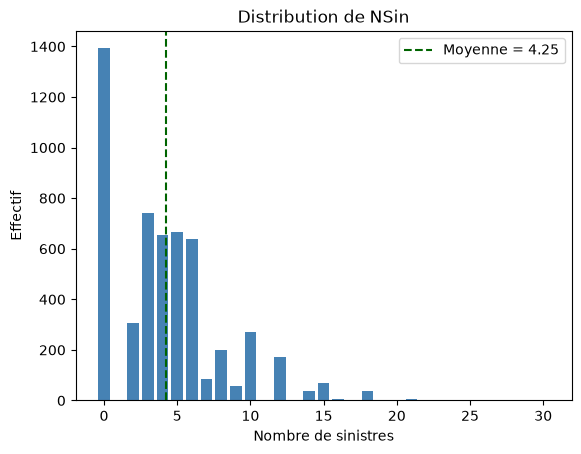

In [12]:
# Distribution de NSin
counts = df["NSin"].value_counts().sort_index()

plt.bar(counts.index, counts.values, color="steelblue")
plt.axvline(mu_nsin, color="darkgreen", linestyle="--", label=f"Moyenne = {mu_nsin:.2f}")
plt.title("Distribution de NSin")
plt.xlabel("Nombre de sinistres")
plt.ylabel("Effectif")
plt.legend()
plt.show()

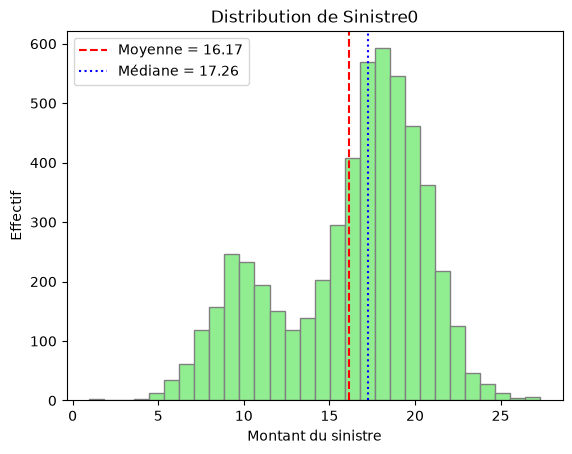

In [13]:
# Distribution de Sinistre0
plt.hist(df["Sinistre0"], bins=30, color="lightgreen", edgecolor="gray")
plt.axvline(df["Sinistre0"].mean(), color="red", linestyle="--", label=f"Moyenne = {df['Sinistre0'].mean():.2f}")
plt.axvline(df["Sinistre0"].median(), color="blue", linestyle=":", label=f"Médiane = {df['Sinistre0'].median():.2f}")
plt.title("Distribution de Sinistre0")
plt.xlabel("Montant du sinistre")
plt.ylabel("Effectif")
plt.legend()
plt.show()

`Sinistre0` : moyenne 16,17, médiane 17,26. La distribution est bimodale, avec un petit mode autour de 9–10 et un mode principal autour de 18–19, séparés par un creux vers 14–15. La moyenne est légèrement inférieure à la médiane (étalement vers les petites valeurs). La bimodalité signale deux sous-populations de sinistres ; l'analyse descriptive ne permet pas de dire à quelles variables elles correspondent.

In [14]:
corr = df[quant_vars].corr()
corr.round(2)

,reves,RUC,Sinistre0,Sinistre1,Sinistre2,Sinistre3,Police1,Police2,Police3,Duree,NSin
reves,1.00,0.07,0.01,-0.00,-0.00,0.01,-0.00,0.01,0.01,0.01,0.01
RUC,0.07,1.00,0.34,-0.02,0.02,-0.07,-0.05,-0.26,-0.08,0.55,-0.20
Sinistre0,0.01,0.34,1.00,-0.02,0.01,-0.08,0.00,-0.28,-0.10,0.26,-0.22
Sinistre1,-0.00,-0.02,-0.02,1.00,0.04,-0.00,0.03,0.07,0.08,0.07,0.18
Sinistre2,-0.00,0.02,0.01,0.04,1.00,0.01,0.03,0.03,0.01,0.00,0.20
Sinistre3,0.01,-0.07,-0.08,-0.00,0.01,1.00,0.05,0.14,0.13,-0.09,0.35
Police1,-0.00,-0.05,0.00,0.03,0.03,0.05,1.00,0.15,0.03,0.01,0.09
Police2,0.01,-0.26,-0.28,0.07,0.03,0.14,0.15,1.00,0.27,-0.19,0.30
Police3,0.01,-0.08,-0.10,0.08,0.01,0.13,0.03,0.27,1.00,-0.08,0.17
Duree,0.01,0.55,0.26,0.07,0.00,-0.09,0.01,-0.19,-0.08,1.00,-0.17


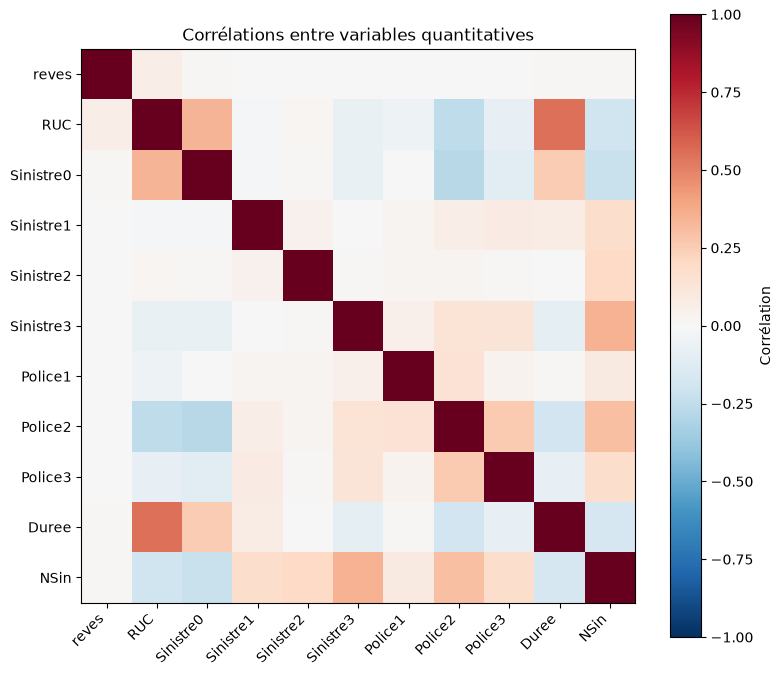

In [15]:
# Heatmap de la matrice de corrélation
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(quant_vars)))
ax.set_xticklabels(quant_vars, rotation=45, ha="right")
ax.set_yticks(range(len(quant_vars)))
ax.set_yticklabels(quant_vars)

plt.colorbar(im, label="Corrélation")
plt.title("Corrélations entre variables quantitatives")
plt.tight_layout()
plt.show()

Les corrélations (de Pearson) sont globalement faibles. Les plus marquées sont :
- `RUC` et `Duree` : 0,55 ;
- `RUC` et `Sinistre0` : 0,34 ; `Sinistre0` et `Duree` : 0,26 ;
- `Sinistre0` et `Police2` : −0,28 ;
- `NSin` et `Sinistre3` : 0,35 ; `NSin` et `Police2` : 0,30 ; `NSin` et `Sinistre2` : 0,20.

`reves` est corrélé à moins de 0,10 avec toutes les autres variables. Sa distribution est très étalée (maximum de 3,4 millions pour une médiane de 11 250), ce qui limite l'information qu'apporte un coefficient de corrélation linéaire sur cette variable. Les variables `Sinistre1`, `Sinistre2` et `Sinistre3` comportent beaucoup de zéros, et une corrélation de Pearson mesure mal leur lien avec les autres variables.

## Synthèse de la Partie 1

- **Données** : 5 352 ménages, 27 variables, aucune valeur manquante.
- **Profil** : les retraités (25,6 %) et les ouvriers (24,8 %) forment les deux catégories socio-professionnelles les plus fréquentes ; 62 % des ménages sont propriétaires et 43,8 % appartiennent à la classe de revenus « moyenne inférieure ».
- **Nombre de sinistres (`NSin`)** : moyenne 4,25, rapport variance/moyenne de 3,42, soit une forte surdispersion. Elle motive la Binomiale Négative et le ZINB (Partie 4).
- **Montant (`Sinistre0`)** : normalité rejetée (Shapiro-Wilk, p ≈ 1·10⁻³⁸) ; distribution bimodale, légèrement étalée vers les petites valeurs. Elle est modélisée en Partie 2 par OLS sur le logarithme et par un GLM Gamma.
- **Proportion de zéros** : 76,33 % pour `Sinistre1`, 89,63 % pour `Sinistre2` et 33,26 % pour `Sinistre3`. `Sinistre2` (89,63 % de zéros) est la variable censurée étudiée en Partie 3.
- **Corrélations** : liens modérés entre `RUC`, `Duree` et `Sinistre0` (0,55 et 0,34) ; `NSin` est surtout associé à `Sinistre3` (0,35) et à `Police2` (0,30).

## Partie 2 — Tarification du coût de sinistre (`Sinistre0`)

Le coût de sinistre `Sinistre0` est modélisé à partir du profil du ménage, selon deux spécifications :

- **a priori** : variables sociodémographiques uniquement (sans `Police1`, `Police2`, `Police3`) ;
- **a posteriori** : avec les trois variables de police, dont l'endogénéité éventuelle est testée.

Deux difficultés sont à traiter : l'hétéroscédasticité des résidus et la non-normalité de `Sinistre0` observée en Partie 1.

### Étape 1 — Données

Tous les ménages ont un `Sinistre0` strictement positif : la base complète est conservée (`dat_pos`).

In [16]:

dat_pos = df[df["Sinistre0"] > 0].copy()
print(dat_pos.shape)

(5352, 27)


### Étape 2 — Modèle a priori : OLS sur log(Sinistre0)

Le modèle a priori régresse log(Sinistre0) sur les variables sociodémographiques, sans les polices. La transformation logarithmique est retenue en raison de la non-normalité de `Sinistre0` (Partie 1). Le résumé ci-dessous est calculé avec des écarts-types robustes HC1, dont le choix est justifié par le test de Breusch-Pagan de l'étape 3.

In [17]:

formule_apriori = (
    "np.log(Sinistre0) ~ RUC + C(pcs) + C(region) + C(Ahabi) + C(Atyph) "
    "+ C(agecat) + C(Acompm) + C(Bauto)"
)
mod_apriori = smf.ols(formule_apriori, data=dat_pos).fit()
mod_apriori_robust = mod_apriori.get_robustcov_results(cov_type="HC1")
print(mod_apriori_robust.summary())
# Composition du ménage : seule Acompm est conservée (nbpers et enfants sont retirées)

                            OLS Regression Results                            
Dep. Variable:      np.log(Sinistre0)   R-squared:                       0.758
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     368.9
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:49:05   Log-Likelihood:                 2356.0
No. Observations:                5352   AIC:                            -4654.
Df Residuals:                    5323   BIC:                            -4463.
Df Model:                          28                                         
Covariance Type:                  HC1                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

R² ajusté = 0,757 : le modèle explique 75,7 % de la variance de log(Sinistre0). Cet ajustement est porté presque exclusivement par deux variables, RUC et la composition du ménage ; les autres variables catégorielles (PCS, région, taille d'agglomération, âge, statut d'occupation, véhicule) n'apportent individuellement presque rien.

Un R² global élevé peut coexister avec de nombreux coefficients individuellement non significatifs lorsque quelques prédicteurs portent l'essentiel du pouvoir explicatif (ici RUC et `Acompm`). Les autres variables sont conservées comme variables de contrôle ; leur faible contribution est un résultat, pas un défaut du modèle.

### Étape 3 — Test d'hétéroscédasticité (Breusch-Pagan)

L'OLS suppose une variance des résidus constante (homoscédasticité). En cas d'hétéroscédasticité, les coefficients restent sans biais et convergents, mais les écarts-types classiques, et donc les p-values, ne sont plus fiables. Le test de Breusch-Pagan (`statsmodels.stats.diagnostic`) est appliqué au modèle a priori.

In [18]:
bp_test = het_breuschpagan(mod_apriori.resid, mod_apriori.model.exog)

lm_stat, lm_pval, f_stat, f_pval = bp_test

print("Statistique LM :", lm_stat)
print("p-value (LM) :", lm_pval)
print("Statistique F :", f_stat)
print("p-value (F) :", f_pval)
# H0 : homoscédasticité (variance des résidus constante)

Statistique LM : 172.1103955461261
p-value (LM) : 1.134034602104537e-22
Statistique F : 6.316624108195912
p-value (F) : 4.2504944589912413e-23


Les deux p-values (LM et F) sont extrêmement faibles (~10⁻²² et ~10⁻²³), très en dessous du seuil conventionnel de 0,05 : on rejette H0.

H0 dans un test de Breusch-Pagan est « la variance des résidus est constante (homoscédasticité) ». En la rejetant, on conclut à la présence d'hétéroscédasticité : la variance des erreurs dépend des variables explicatives et n'est pas constante sur l'échantillon.

**Pourquoi c'est important**

En présence d'hétéroscédasticité, les coefficients OLS restent sans biais et convergents, mais leurs écarts-types « classiques » (non robustes) sont biaisés, dans un sens ou dans l'autre. Les t-stats, p-values et intervalles de confiance qui en découlent ne sont donc plus fiables : une variable peut sembler significative alors qu'elle ne l'est pas, ou l'inverse.

On conserve donc les coefficients et on recalcule uniquement les écarts-types avec l'estimateur robuste de White (HC1). Toutes les conclusions de significativité s'appuient sur ce résumé corrigé (« Covariance Type: HC1 »), jamais sur le résumé non corrigé.

**OLS sur log(Sinistre0)** : les coefficients mesurent l'effet sur log(Sinistre0). La variation relative du sinistre attendu s'obtient avec exp(β) − 1, à lire en pourcentage.

**Lecture du modèle a priori (écarts-types HC1).** Les coefficients sont ceux de l'OLS ; seuls les écarts-types sont recalculés avec l'estimateur de White (HC1). Sous ce résumé corrigé, RUC (p < 0,001) et la composition du ménage, en particulier « Couple avec enfants » (β = −0,605 ; p < 0,001), sont les seuls déterminants significatifs du coût du sinistre. La PCS, la région, la taille d'agglomération, la classe d'âge, le statut d'occupation et le véhicule n'ont pas d'effet individuel significatif.

In [19]:
# Diagnostic de multicolinéarité : facteur d'inflation de la variance (VIF) du modèle a priori

X = mod_apriori.model.exog  # matrice des variables explicatives (indicatrices incluses)
vif_data = pd.DataFrame({
    "variable": mod_apriori.model.exog_names,
    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})
vif_data.sort_values("VIF", ascending=False)

,variable,VIF
7,C(pcs)[T.Retraites],13.354805
5,C(pcs)[T.Ouvriers],9.699134
6,C(pcs)[T.Professions intermediaires],7.657381
8,C(region)[T.2],7.596486
4,C(pcs)[T.Employes],7.148200
11,C(region)[T.5],6.780824
15,C(Ahabi)[T.Paris + Agglomeration],6.429689
13,C(region)[T.8],6.112663
23,C(agecat)[T.61-96],6.062764
10,C(region)[T.4],5.181021


**Seuils usuels de lecture**

- VIF < 5 : pas de souci
- 5 ≤ VIF ≤ 10 : à surveiller
- VIF > 10 : problème sérieux, la variable est fortement redondante avec d'autres

Un seul coefficient dépasse nettement 10 : PCS = Retraités (VIF = 13,35). Ce résultat est cohérent avec celui de agecat = 61-96 (VIF = 6,06, dans la zone à surveiller) : les deux variables se recoupent, puisqu'être retraité implique presque toujours appartenir à la tranche d'âge la plus élevée.

Les autres valeurs comprises entre 5 et 10 (Ouvriers, Professions intermédiaires, plusieurs régions, Paris + agglomération) relèvent de la zone grise. Elles reflètent vraisemblablement des liens réels entre catégorie socioprofessionnelle et localisation, plutôt qu'un artefact numérique à corriger.

**Décision : on conserve toutes les variables**, pour deux raisons :

1. Un seul VIF dépasse nettement 10 : il ne s'agit pas d'une colinéarité généralisée qui rendrait le modèle instable.
2. La relation PCS–âge est informative : retirer pcs ou agecat ferait perdre une information économiquement distincte (le statut de retraité capture aussi la sortie du marché du travail, pas seulement l'âge biologique).

### Étape 5 — Modèle a posteriori (ajout des polices)

On enrichit le modèle a priori avec Police1, Police2 et Police3, les dépenses de couverture du ménage.

In [20]:

formule_aposteriori = (
    "np.log(Sinistre0) ~ RUC + C(pcs) + C(region) + C(Ahabi) + C(Atyph) "
    "+ C(agecat) + C(Acompm) + C(Bauto) + Police1 + Police2 + Police3"
)
mod_aposteriori = smf.ols(formule_aposteriori, data=dat_pos).fit()
mod_aposteriori_robust = mod_aposteriori.get_robustcov_results(cov_type="HC1")
print(mod_aposteriori_robust.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(Sinistre0)   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     333.8
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:49:06   Log-Likelihood:                 2358.0
No. Observations:                5352   AIC:                            -4652.
Df Residuals:                    5320   BIC:                            -4441.
Df Model:                          31                                         
Covariance Type:                  HC1                                         
                                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

**Comparaison avec le modèle a priori.** R² = 0,759 (0,757 ajusté) contre 0,758 (0,757 ajusté) pour le modèle a priori : l'ajout des polices n'apporte aucun gain explicatif, et l'AIC et le BIC sont plus bas pour le modèle a priori. Les coefficients des variables communes restent quasi identiques (par exemple, Acompm[Couple avec enfants] reste à −0,605).

**Polices.** Aucune des trois n'est significative à 5 % : p = 0,137 (Police1), 0,587 (Police2) et 0,419 (Police3).

**Conclusion intermédiaire.** Ajouter les dépenses de couverture n'améliore pas le modèle : ni le R², ni la significativité individuelle des trois variables. Les déterminants du coût du sinistre restent les mêmes qu'a priori : RUC et composition du ménage. Une interprétation possible, non testée, est que les montants de police reflètent un niveau de couverture souscrit plutôt qu'un indicateur de risque : un ménage qui paie plus cher pour être mieux couvert n'a pas nécessairement des sinistres plus coûteux.

### Test F conjoint

Tester les trois variables une par une n'équivaut pas à tester leur utilité d'ensemble (une variable peut sembler non significative à cause de la colinéarité avec les autres, alors que le bloc l'est). On teste donc H0 : Police1 = Police2 = Police3 = 0, avec la covariance robuste HC1.

In [21]:
hypotheses = "Police1 = 0, Police2 = 0, Police3 = 0"
f_test = mod_aposteriori_robust.f_test(hypotheses)  # covariance HC1
print(f_test)

<F test: F=1.252534827510324, p=0.28897112622926996, df_denom=5.32e+03, df_num=3>


Le test F conjoint (H0 : Police1 = Police2 = Police3 = 0), calculé avec la covariance robuste HC1, donne F = 1,25 ; p = 0,289. On ne rejette pas H0 : les trois polices ne sont pas conjointement significatives, ce qui confirme formellement la lecture des p-values individuelles.

In [22]:
lm, lm_p, f, f_p = het_breuschpagan(mod_aposteriori.resid, mod_aposteriori.model.exog)
print(f"Breusch-Pagan (a posteriori) : LM = {lm:.1f} (p = {lm_p:.1e}) | F = {f:.2f} (p = {f_p:.1e})")

Breusch-Pagan (a posteriori) : LM = 173.7 (p = 8.8e-22) | F = 5.76 (p = 3.4e-22)


Le test de Breusch-Pagan confirme l'hétéroscédasticité dans le modèle a posteriori, comme pour le modèle a priori (LM = 173,7 ; p = 8,8×10⁻²²). Les écarts-types sont donc corrigés par HC1.

### Étape 6 — Endogénéité des polices (Hausman / IV-2SLS)

Même si les polices ne sont pas significatives par OLS, leur endogénéité potentielle doit être testée : un ménage qui anticipe un risque élevé pourrait souscrire une meilleure couverture (sélection adverse), ce qui biaiserait le coefficient OLS même s'il paraît nul.

### Estimation par doubles moindres carrés (2SLS)

1. **Première étape** : on régresse chaque variable endogène sur les instruments et les variables exogènes, pour obtenir X̂, la partie de X expliquée par Z.
2. **Seconde étape** : on régresse Y sur X̂ (au lieu de X). L'estimateur de β obtenu est convergent si les instruments sont valides (pertinents et exogènes).

In [23]:
# 1. Variable réponse + exogènes (avec intercept)
y, X_exog = patsy.dmatrices(
    "np.log(Sinistre0) ~ RUC + C(pcs) + C(region) + C(Ahabi) + C(Atyph) "
    "+ C(agecat) + C(Acompm) + C(Bauto)",
    data=dat_pos, return_type="dataframe"
)

# 2. Variables endogènes (celles qu'on soupçonne)
X_endog = dat_pos[["Police1", "Police2", "Police3"]]

# 3. Instruments exclus (sans intercept, patsy en génère un par défaut qu'on retire)
_, Z_instr = patsy.dmatrices(
    "1 ~ Duree + C(crevpp)", data=dat_pos, return_type="dataframe"
)
Z_instr = Z_instr.drop(columns="Intercept")


# 4. Estimation IV2SLS
mod_iv = IV2SLS(y, X_exog, X_endog, Z_instr).fit(cov_type="robust")
print(mod_iv.params.filter(like="Police").round(4))
print(mod_iv.pvalues.filter(like="Police").round(3))
print(mod_iv.first_stage.diagnostics.round(4))
#print(mod_iv.summary)

Police1   -0.0004
Police2   -0.0030
Police3    0.0024
Name: parameter, dtype: float64
Police1    0.929
Police2    0.203
Police3    0.946
Name: pvalue, dtype: float64
         rsquared  partial.rsquared  shea.rsquared   f.stat  f.pval   f.dist
Police1    0.0572            0.0092         0.0085  48.0455  0.0000  chi2(4)
Police2    0.2260            0.0164         0.0062  76.0236  0.0000  chi2(4)
Police3    0.1063            0.0023         0.0008  12.4842  0.0141  chi2(4)


**Force des instruments (première étape).** Chaque police est régressée sur les variables exogènes et les instruments (Duree, crevpp). Statistique de Wald robuste sur les 4 instruments (χ² à 4 ddl) : Police1 = 48,05 (p < 0,001) ; Police2 = 76,02 (p < 0,001) ; Police3 = 12,48 (p = 0,014). Rapportées au nombre d'instruments, ces valeurs correspondent à des F d'environ 12,0, 19,0 et 3,1. Les instruments sont donc significatifs pour les trois polices, mais seuls Police1 (de peu) et Police2 dépassent le seuil usuel de 10 ; Police3 est faiblement instrumentée (F ≈ 3,1). Les R² partiels sont par ailleurs très faibles (0,9 %, 1,6 % et 0,2 %) : les instruments expliquent peu la variation des polices. Un instrument faible rapproche l'estimateur 2SLS de l'OLS et réduit la puissance du test d'endogénéité ; les résultats IV sont à interpréter avec prudence.

**Coefficients IV des polices** : Police1 = −0,0004 (p = 0,93) ; Police2 = −0,0030 (p = 0,20) ; Police3 = +0,0024 (p = 0,95). Aucune n'est significative, comme en OLS.

In [24]:
# Tests de diagnostic (endogénéité + validité des instruments)
print("=== Test de Wu-Hausman (endogénéité) ===")
print(mod_iv.wu_hausman())

print("\n=== Test de Sargan (validité des instruments, 1 degré de sur-identification) ===")
print(mod_iv.sargan)

# Versions robustes à l'hétéroscédasticité
print("\n=== Endogénéité (Wooldridge, robuste) ===")
print(mod_iv.wooldridge_regression)

print("\n=== Sur-identification (Wooldridge, robuste) ===")
print(mod_iv.wooldridge_overid)

=== Test de Wu-Hausman (endogénéité) ===
Wu-Hausman test of exogeneity
H0: All endogenous variables are exogenous
Statistic: 1.6493
P-value: 0.1758
Distributed: F(3,5317)

=== Test de Sargan (validité des instruments, 1 degré de sur-identification) ===
Sargan's test of overidentification
H0: The model is not overidentified.
Statistic: 0.0330
P-value: 0.8559
Distributed: chi2(1)

=== Endogénéité (Wooldridge, robuste) ===
Wooldridge's regression test of exogeneity
H0: Endogenous variables are exogenous
Statistic: 5.0053
P-value: 0.1714
Distributed: chi2(3)

=== Sur-identification (Wooldridge, robuste) ===
Wooldridge's score test of overidentification
H0: Model is not overidentified.
Statistic: 0.0410
P-value: 0.8396
Distributed: chi2(1)


### Tests de diagnostic

**Test de Wu-Hausman (endogénéité)**

H0 : les variables Police1/2/3 sont exogènes.

Statistique F(3 ; 5 317) = 1,65 ; p = 0,176 (version robuste de Wooldridge : χ²(3) = 5,01 ; p = 0,171). On ne rejette pas H0.

Conclusion : on ne détecte pas d'endogénéité significative des polices, malgré la crainte théorique de sélection adverse. Ce résultat ne prouve pas l'exogénéité : la puissance du test est limitée par la faiblesse des instruments, notamment pour Police3. En pratique, les coefficients des polices ne sont significatifs ni en OLS ni en IV, donc le choix de l'estimateur ne change pas la conclusion sur leur effet.

**Test de Sargan (validité des instruments)**

H0 : les restrictions de sur-identification sont valides, c'est-à-dire que les instruments sont non corrélés avec l'erreur du modèle.

Statistique = 0,033 ; p = 0,856 (version robuste de Wooldridge : 0,041 ; p = 0,840). On ne rejette pas H0.

Conclusion : les 4 instruments (Duree + 3 indicatrices de crevpp), utilisés pour 3 variables endogènes, sont statistiquement cohérents entre eux : rien n'indique qu'un d'eux soit corrélé à l'erreur. Le test n'a qu'un degré de liberté et ne démontre pas à lui seul l'exogénéité des instruments, qui reste une hypothèse à argumenter.

### Étape 7 — GLM Gamma à lien log

`Sinistre0` est une variable continue strictement positive : le GLM Gamma à lien logarithmique modélise directement son espérance, sans transformer la variable. Deux modèles sont estimés (a priori et a posteriori), puis comparés.

In [25]:
formule_glm_apriori = (
    "Sinistre0 ~ RUC + C(pcs) + C(region) + C(Ahabi) + C(Atyph) "
    "+ C(agecat) + C(Acompm) + C(Bauto)"
)
glm_apriori = smf.glm(
    formule_glm_apriori, data=dat_pos,
    family=sm.families.Gamma(link=sm.families.links.Log())
).fit()
print(glm_apriori.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:              Sinistre0   No. Observations:                 5352
Model:                            GLM   Df Residuals:                     5323
Model Family:                   Gamma   Df Model:                           28
Link Function:                    Log   Scale:                        0.021515
Method:                          IRLS   Log-Likelihood:                -12164.
Date:                Wed, 14 Oct 2026   Deviance:                       122.58
Time:                        16:49:08   Pearson chi2:                     115.
No. Iterations:                     9   Pseudo R-squ. (CS):             0.9519
Covariance Type:            nonrobust                                         
                                                     coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

**GLM Gamma a priori (sans les polices).** La structure de significativité est la même que dans l'OLS sur log(Sinistre0) :

- RUC : hautement significatif (p < 0,001) ;
- `Acompm` = Couple avec enfant(s) : β = −0,5887 ; p < 0,001, le facteur dominant ;
- toutes les autres variables (PCS, région, `Ahabi`, `Atyph`, `agecat`, `Bauto`) : non significatives individuellement (p > 0,17).

Deux spécifications différentes (OLS log-linéaire et GLM Gamma à lien log) conduisent à la même conclusion : seuls RUC et la composition du ménage déterminent le coût du sinistre dans ce portefeuille.

In [26]:
formule_glm_aposteriori = (
    "Sinistre0 ~ RUC + C(pcs) + C(region) + C(Ahabi) + C(Atyph) "
    "+ C(agecat) + C(Acompm) + C(Bauto) + Police1 + Police2 + Police3"
)
glm_aposteriori = smf.glm(
    formule_glm_aposteriori, data=dat_pos,
    family=sm.families.Gamma(link=sm.families.links.Log())
).fit()
print(glm_aposteriori.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:              Sinistre0   No. Observations:                 5352
Model:                            GLM   Df Residuals:                     5320
Model Family:                   Gamma   Df Model:                           31
Link Function:                    Log   Scale:                        0.021510
Method:                          IRLS   Log-Likelihood:                -12162.
Date:                Wed, 14 Oct 2026   Deviance:                       122.49
Time:                        16:49:08   Pearson chi2:                     114.
No. Iterations:                     9   Pseudo R-squ. (CS):             0.9520
Covariance Type:            nonrobust                                         
                                                     coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

In [27]:
glm_apriori_hc1 = smf.glm(
    formule_glm_apriori, data=dat_pos,
    family=sm.families.Gamma(link=sm.families.links.Log())
).fit(cov_type="HC1")

comp = pd.DataFrame({"p classique": glm_apriori.pvalues, "p HC1": glm_apriori_hc1.pvalues})
print(comp.round(3))
print("Mêmes variables significatives à 5 % :",
      ((comp["p classique"] < 0.05) == (comp["p HC1"] < 0.05)).all())

                                                p classique  p HC1
Intercept                                             0.000  0.000
C(pcs)[T.Artisans, comm., chefs d'ent.]               0.599  0.601
C(pcs)[T.Autres pers. sans activite prof.]            0.894  0.892
C(pcs)[T.Cadres et prof. intellectuelles sup.]        0.463  0.483
C(pcs)[T.Employes]                                    0.883  0.890
C(pcs)[T.Ouvriers]                                    0.372  0.404
C(pcs)[T.Professions intermediaires]                  0.643  0.660
C(pcs)[T.Retraites]                                   0.953  0.951
C(region)[T.2]                                        0.179  0.187
C(region)[T.3]                                        0.253  0.254
C(region)[T.4]                                        0.383  0.389
C(region)[T.5]                                        0.444  0.446
C(region)[T.7]                                        0.979  0.979
C(region)[T.8]                                        0.282  0

**Robustesse de la covariance.** Avec des écarts-types robustes HC1, les p-values changent peu et les mêmes variables restent significatives à 5 % (RUC et la composition du ménage). Les conclusions du GLM Gamma ne dépendent donc pas de l'hypothèse de variance du modèle.

In [28]:
print("=== Comparaison AIC/LogLik ===")
print(f"GLM a priori     : AIC={glm_apriori.aic:.2f} | LogLik={glm_apriori.llf:.2f}")
print(f"GLM a posteriori : AIC={glm_aposteriori.aic:.2f} | LogLik={glm_aposteriori.llf:.2f}")

# Test du rapport de vraisemblance (LRT) — a priori vs a posteriori
lrt_stat = 2 * (glm_aposteriori.llf - glm_apriori.llf)
ddl = glm_aposteriori.df_model - glm_apriori.df_model
pval_lrt = stats.chi2.sf(lrt_stat, ddl)
print(f"\nLRT : chi²={lrt_stat:.3f}, ddl={ddl:.0f}, p={pval_lrt:.4f}")

=== Comparaison AIC/LogLik ===
GLM a priori     : AIC=24385.66 | LogLik=-12163.83
GLM a posteriori : AIC=24387.57 | LogLik=-12161.78

LRT : chi²=4.094, ddl=3, p=0.2515


**Comparaison avec le modèle a priori.** AIC = 24 387,57 pour le modèle a posteriori contre 24 385,66 pour le modèle a priori. L'ajout des polices dégrade très légèrement l'AIC : la pénalisation des trois paramètres supplémentaires n'est pas compensée par un gain de vraisemblance. Le test du rapport de vraisemblance ne rejette pas le modèle a priori (χ² = 4,09 ; 3 ddl ; p = 0,25 ; test approché, la dispersion étant estimée). Le pseudo-R² de Cox-Snell (0,952) est une mesure interne au GLM, qui n'est pas comparable au R² d'une régression linéaire et ne s'interprète pas comme une part de variance expliquée.

**Polices (au seuil de 5 %, aucune n'est significative)**

- Police1 : coef = 0,0007 ; p = 0,096 (significatif à 10 %, pas à 5 %)
- Police2 : coef ≈ 0,0001 ; p = 0,577
- Police3 : coef = 0,0006 ; p = 0,474

**Autres variables.** Les résultats restent stables. Acompm[Couple avec enfants] reste le facteur dominant (coef = −0,589 ; p < 0,001) et RUC reste très significatif (p < 0,001). Toutes les autres variables (PCS, région, taille d'agglomération, âge, statut d'occupation, véhicule) restent non significatives, comme dans le modèle a priori : l'ajout des polices ne change quasiment rien à la structure du modèle.

### Bilan de la Partie 2

Trois critères convergent vers la même décision : l'AIC (plus faible pour le modèle a priori), le test du rapport de vraisemblance (non-rejet) et la significativité individuelle (aucune police significative à 5 %). Le **modèle retenu est le GLM Gamma a priori** (AIC = 24 385,66), le plus parcimonieux, qui sert de base à la suite : diagnostics graphiques et grille tarifaire. Il est cohérent avec l'OLS sur log(Sinistre0) : mêmes variables significatives (RUC et composition du ménage), avec des conclusions inchangées sous écarts-types robustes.

### Grille tarifaire

On calcule les relativités exp(β) du GLM Gamma a priori retenu, puis on prédit quelques profils types.

**Pourquoi exp(β) et non β ?** Le GLM Gamma a un lien logarithmique : le modèle estime log(E[Sinistre0]) et non Sinistre0 :

log(E[Sinistre0]) = β₀ + β₁ × RUC + β₂ × [Couple avec enfants] + …

En prenant l'exponentielle des deux côtés, on revient à l'échelle des montants :

E[Sinistre0] = exp(β₀) × exp(β₁ × RUC) × exp(β₂ × [Couple avec enfants]) × …

Le modèle est additif en log mais **multiplicatif en niveau** : exp(β) est une *relativité*, un facteur par lequel on multiplie le coût de base, et non un montant que l'on ajoute. C'est pourquoi le lien log est le choix standard en tarification non-vie : il produit des relativités directement interprétables et exploitables commercialement.

**Lecture des résultats**

- exp(Intercept) = 17,32 unités monétaires : coût attendu du profil de référence (modalités de référence, RUC = 0). C'est le coût de base.
- Acompm = Couple avec enfant(s) : ×0,555, soit un coût attendu 44,5 % plus bas que la référence, toutes choses égales par ailleurs.
- agecat = 61-96 : ×0,992 (−0,8 %) : effet négligeable et non significatif ; l'âge ne discrimine pratiquement pas le coût dans ce modèle.

In [29]:
# Relativités tarifaires = exp(coefficients) du modèle a priori retenu, avec IC à 95 %
ic = glm_apriori.conf_int()
grille = pd.DataFrame({
    "relativité": np.exp(glm_apriori.params),
    "IC95 bas": np.exp(ic[0]),
    "IC95 haut": np.exp(ic[1]),
    "p-value": glm_apriori.pvalues,
}).round(3)

prime_base = np.exp(glm_apriori.params["Intercept"])
print(f"Coût de base (Intercept) : {prime_base:.2f} (unités monétaires)\n")

display(grille.drop(index="Intercept"))
print(f"RUC : +10 000 unités → ×{np.exp(glm_apriori.params['RUC'] * 10_000):.3f}")

Coût de base (Intercept) : 17.32 (unités monétaires)



,relativité,IC95 bas,IC95 haut,p-value
"C(pcs)[T.Artisans, comm., chefs d'ent.]",1.009,0.975,1.045,0.599
C(pcs)[T.Autres pers. sans activite prof.],1.002,0.968,1.038,0.894
C(pcs)[T.Cadres et prof. intellectuelles sup.],1.012,0.981,1.044,0.463
C(pcs)[T.Employes],0.998,0.969,1.028,0.883
C(pcs)[T.Ouvriers],0.987,0.960,1.016,0.372
C(pcs)[T.Professions intermediaires],0.993,0.964,1.023,0.643
C(pcs)[T.Retraites],0.999,0.967,1.032,0.953
C(region)[T.2],0.981,0.954,1.009,0.179
C(region)[T.3],0.982,0.953,1.013,0.253
C(region)[T.4],0.987,0.959,1.016,0.383


RUC : +10 000 unités → ×1.119


**Lecture de la grille.** À l'exception de Couple avec enfant(s) et de RUC, aucune relativité n'est significativement différente de 1 : leurs intervalles de confiance à 95 % contiennent 1. Les écarts affichés (de l'ordre de ±1 %) relèvent du bruit d'estimation et ne doivent pas être interprétés comme des effets. La relativité de RUC est exprimée par unité (d'où l'affichage de 1,000 après arrondi) : pour un écart de 10 000 unités, elle vaut ×1,119.

Un ménage « Couple avec enfants » a un coût attendu 44,5 % plus bas que la référence (« Autre ménage »), toutes choses égales par ailleurs. Ce résultat est contre-intuitif au premier abord (on pourrait s'attendre à davantage de sinistres pour une famille avec enfants), mais il est cohérent avec l'OLS de la Partie 2 (coefficient de −0,605 en log, soit environ −45 %). Plusieurs explications sont possibles mais non testées ici (type de garanties souscrites, profil de logement). Le jeu de données étant fictif, ce résultat ne se généralise pas à un portefeuille réel.

### Coût attendu pour des profils types

Cinq profils représentatifs sont construits et leur coût de sinistre attendu est prédit avec `glm_apriori`. Les modalités exactes de chaque variable sont d'abord listées pour éviter les erreurs de niveau.

In [30]:
# Modalités exactes de chaque variable catégorielle
print("pcs:", dat_pos["pcs"].cat.categories.tolist())
print("Ahabi:", dat_pos["Ahabi"].cat.categories.tolist())
print("Atyph:", dat_pos["Atyph"].cat.categories.tolist())
print("agecat:", dat_pos["agecat"].cat.categories.tolist())
print("Acompm:", dat_pos["Acompm"].cat.categories.tolist())
print("Bauto:", dat_pos["Bauto"].cat.categories.tolist())

pcs: ['Agr. exploitants', "Artisans, comm., chefs d'ent.", 'Autres pers. sans activite prof.', 'Cadres et prof. intellectuelles sup.', 'Employes', 'Ouvriers', 'Professions intermediaires', 'Retraites']
Ahabi: ['Communes rurales', 'Paris + Agglomeration', 'Un. urb. de 10 000 a 99 999 hab.', 'Un. urb. de 100 000 hab. et +', 'Un. urb. de 2 000 a 9 999 hab.']
Atyph: ['Locataire', 'Non declare', 'Proprietaire']
agecat: ['21-40', '41-50', '51-60', '61-96']
Acompm: ['Autre menage', 'Couple avec enfant(s)', 'Couple sans enfant', 'Personne seule']
Bauto: ['Au - 1 vehicule', 'Pas de vehicule']


In [31]:
profils = pd.DataFrame({
    "Profil": [
        "Locataire urbain actif (réf)",
        "Propriétaire rural inactif",
        "Locataire Paris, jeune actif",
        "Propriétaire gr. ville, couple enfants",
        "Locataire modeste, personne seule",
    ],
    "pcs": pd.Categorical(
        ["Employes", "Retraites", "Artisans, comm., chefs d'ent.", "Cadres et prof. intellectuelles sup.", "Ouvriers"],
        categories=dat_pos["pcs"].cat.categories
    ),
    "region": pd.Categorical(
        [1, 3, 1, 4, 2],
        categories=dat_pos["region"].cat.categories
    ),
    "Ahabi": pd.Categorical(
        ["Un. urb. de 100 000 hab. et +", "Communes rurales", "Paris + Agglomeration",
         "Un. urb. de 100 000 hab. et +", "Un. urb. de 10 000 a 99 999 hab."],
        categories=dat_pos["Ahabi"].cat.categories
    ),
    "Atyph": pd.Categorical(
        ["Locataire", "Proprietaire", "Locataire", "Proprietaire", "Locataire"],
        categories=dat_pos["Atyph"].cat.categories
    ),
    "agecat": pd.Categorical(
        ["21-40", "61-96", "21-40", "41-50", "51-60"],
        categories=dat_pos["agecat"].cat.categories, ordered=True
    ),
    "Acompm": pd.Categorical(
        ["Autre menage", "Autre menage", "Autre menage", "Couple avec enfant(s)", "Personne seule"],
        categories=dat_pos["Acompm"].cat.categories
    ),
    "Bauto": pd.Categorical(
        ["Au - 1 vehicule", "Au - 1 vehicule", "Pas de vehicule", "Au - 1 vehicule", "Au - 1 vehicule"],
        categories=dat_pos["Bauto"].cat.categories
    ),
    "RUC": [5500, 7000, 8000, 6000, 3000],
})

pred = glm_apriori.get_prediction(profils).summary_frame()
profils["Cout_attendu"] = pred["mean"].round(2)
profils["IC95 bas"] = pred["mean_ci_lower"].round(2)
profils["IC95 haut"] = pred["mean_ci_upper"].round(2)

display(profils[["Profil", "pcs", "region", "Ahabi", "Atyph", "agecat", "Acompm", "Bauto", "RUC",
                 "Cout_attendu", "IC95 bas", "IC95 haut"]])

,Profil,pcs,region,Ahabi,Atyph,agecat,Acompm,Bauto,RUC,Cout_attendu,IC95 bas,IC95 haut
0,Locataire urbain actif (réf),Employes,1,Un. urb. de 100 000 hab. et +,Locataire,21-40,Autre menage,Au - 1 vehicule,5500,18.37,17.82,18.95
1,Propriétaire rural inactif,Retraites,3,Communes rurales,Proprietaire,61-96,Autre menage,Au - 1 vehicule,7000,18.25,17.88,18.63
2,"Locataire Paris, jeune actif","Artisans, comm., chefs d'ent.",1,Paris + Agglomeration,Locataire,21-40,Autre menage,Pas de vehicule,8000,18.91,18.35,19.49
3,"Propriétaire gr. ville, couple enfants",Cadres et prof. intellectuelles sup.,4,Un. urb. de 100 000 hab. et +,Proprietaire,41-50,Couple avec enfant(s),Au - 1 vehicule,6000,10.27,10.05,10.49
4,"Locataire modeste, personne seule",Ouvriers,2,Un. urb. de 10 000 a 99 999 hab.,Locataire,51-60,Personne seule,Au - 1 vehicule,3000,17.03,16.66,17.41


**Lecture.** Quatre des cinq profils ont un coût attendu proche (de 17,0 à 18,9 unités monétaires). Le profil « couple avec enfants » se détache nettement (10,27 ; IC 95 % [10,05 ; 10,49]), ce qui correspond à la relativité de ×0,555. Pour les quatre autres, les écarts viennent pour l'essentiel de RUC, seule autre variable significative : les intervalles des profils 1, 2 et 3 se chevauchent, tandis que le profil au RUC le plus bas (3 000) est significativement plus bas que les autres. Les effets de la PCS, de la région, de la taille d'agglomération ou de l'âge n'étant pas significatifs, ces écarts ne doivent pas être lus comme des différences de risque liées à ces variables. Les intervalles ne reflètent que l'incertitude d'estimation de la moyenne, pas la variabilité d'un sinistre individuel. Les montants sont exprimés en unités monétaires arbitraires.

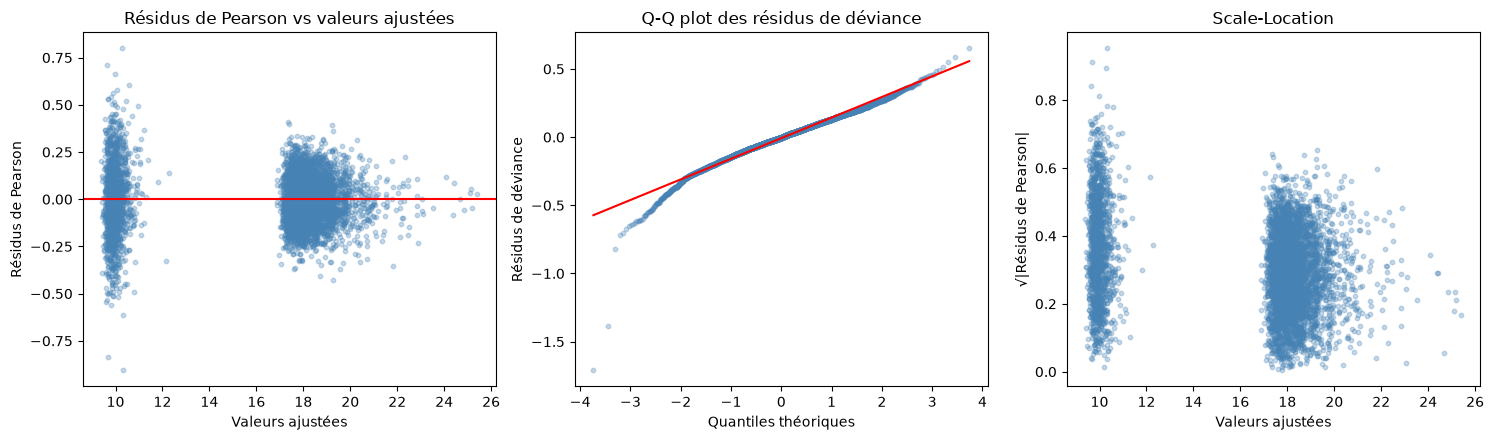

In [32]:
fitted = glm_apriori.fittedvalues
resid_pearson = glm_apriori.resid_pearson
resid_deviance = glm_apriori.resid_deviance

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Résidus de Pearson vs valeurs ajustées
axes[0].scatter(fitted, resid_pearson, alpha=0.3, s=10, color="steelblue")
axes[0].axhline(0, color="red", lw=1.5)
axes[0].set_xlabel("Valeurs ajustées")
axes[0].set_ylabel("Résidus de Pearson")
axes[0].set_title("Résidus de Pearson vs valeurs ajustées")

# 2. QQ-plot des résidus de déviance
sorted_resid = np.sort(resid_deviance)
n = len(sorted_resid)
theoretical_q = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
axes[1].scatter(theoretical_q, sorted_resid, alpha=0.3, s=10, color="steelblue")
axes[1].plot(theoretical_q, theoretical_q * sorted_resid.std() + sorted_resid.mean(),
             color="red", lw=1.5)
axes[1].set_xlabel("Quantiles théoriques")
axes[1].set_ylabel("Résidus de déviance")
axes[1].set_title("Q-Q plot des résidus de déviance")

# 3. Scale-Location : racine de la valeur absolue des résidus de Pearson vs valeurs ajustées
axes[2].scatter(fitted, np.sqrt(np.abs(resid_pearson)), alpha=0.3, s=10, color="steelblue")
axes[2].set_xlabel("Valeurs ajustées")
axes[2].set_ylabel("√|Résidus de Pearson|")
axes[2].set_title("Scale-Location")

plt.tight_layout()
plt.show()

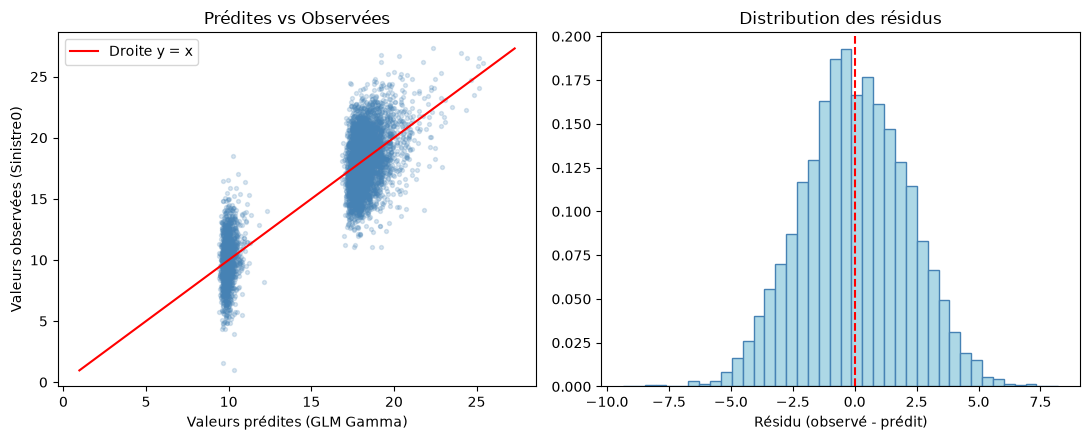

RMSE (GLM Gamma a priori, en échantillon) : 2.1450 unités monétaires
MAE  (GLM Gamma a priori, en échantillon) : 1.7179 unités monétaires


In [33]:
# Prédites vs observées + distribution des résidus
pred_glm = glm_apriori.predict(dat_pos)
resid_glm = dat_pos["Sinistre0"] - pred_glm

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(pred_glm, dat_pos["Sinistre0"], alpha=0.2, s=8, color="steelblue")
lims = [dat_pos["Sinistre0"].min(), dat_pos["Sinistre0"].max()]
axes[0].plot(lims, lims, color="red", lw=1.5, label="Droite y = x")
axes[0].set_xlabel("Valeurs prédites (GLM Gamma)")
axes[0].set_ylabel("Valeurs observées (Sinistre0)")
axes[0].set_title("Prédites vs Observées")
axes[0].legend()

axes[1].hist(resid_glm, bins=40, color="lightblue", edgecolor="steelblue", density=True)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Résidu (observé - prédit)")
axes[1].set_title("Distribution des résidus")

plt.tight_layout()
plt.show()

rmse = np.sqrt((resid_glm**2).mean())
mae = resid_glm.abs().mean()
print(f"RMSE (GLM Gamma a priori, en échantillon) : {rmse:.4f} unités monétaires")
print(f"MAE  (GLM Gamma a priori, en échantillon) : {mae:.4f} unités monétaires")

In [34]:
grp = np.where(dat_pos["Acompm"] == "Couple avec enfant(s)", "Couple avec enfants", "Autres")
print(pd.DataFrame({"grp": grp, "résidu brut": resid_glm,
                    "résidu Pearson": glm_apriori.resid_pearson}).groupby("grp").std().round(3))

                     résidu brut  résidu Pearson
grp                                             
Autres                     2.175           0.119
Couple avec enfants        2.057           0.206


### Diagnostics du GLM Gamma

**Résidus de Pearson vs valeurs ajustées.** Les résidus forment deux nuages séparés (valeurs ajustées ≈ 10 et ≈ 18). Ce n'est pas un défaut de spécification : il reflète la variable dominante du modèle, Couple avec enfant(s) (β = −0,589, soit ×0,555), qui forme le nuage bas, les autres profils formant le nuage haut. Les résidus sont centrés sur zéro dans chaque nuage, sans tendance systématique. Leur dispersion est en revanche plus forte dans le nuage bas que dans le nuage haut, ce que confirme le graphique Scale-Location.

**Fonction de variance.** Une loi Gamma suppose un coefficient de variation constant, donc des résidus de Pearson de même dispersion partout. Ce n'est pas le cas ici : l'écart-type des résidus de Pearson est de 0,119 pour les « Autres » ménages contre 0,206 pour les « Couples avec enfants », alors que celui des résidus bruts est quasi identique dans les deux groupes (2,175 contre 2,057). La variance est donc plutôt constante en niveau que proportionnelle à μ², et la fonction de variance Gamma est une approximation imparfaite. L'espérance conditionnelle reste correctement modélisée, et les conclusions de significativité sont inchangées sous écarts-types robustes HC1 (voir plus haut).

**Q-Q plot des résidus de déviance.** Les points suivent la droite sur presque toute la distribution ; seule la queue gauche s'en écarte (quelques sinistres nettement plus faibles que prédits).

**Valeurs prédites vs observées.** Le modèle sépare bien les deux groupes, mais à l'intérieur de chacun les prédictions varient peu alors que les valeurs observées s'étalent largement : le pouvoir de discrimination vient presque entièrement de la composition du ménage, RUC apportant un complément mineur.

**Résidus bruts.** Ils sont symétriques et centrés sur zéro. RMSE = 2,15 et MAE = 1,72 unités monétaires, calculés sur l'échantillon d'estimation, sans jeu de test : ils sont donc plutôt optimistes.

### Bilan de la Partie 2 : tarification a priori / a posteriori du coût de sinistre

**1. Cadre et données.** La modélisation porte sur les 5 352 ménages de la base, tous avec Sinistre0 > 0 (aucun ménage n'est exclu). La variable réponse est transformée en log(Sinistre0) pour l'OLS, en cohérence avec le rejet de la normalité observé en Partie 1 (Shapiro-Wilk). Les montants sont exprimés en unités monétaires arbitraires.

**2. Modèles OLS a priori et a posteriori.**

- *Ajustement.* Le modèle a priori a un R² de 0,758 (0,757 ajusté), le modèle a posteriori de 0,759 (0,757 ajusté) : l'ajout des polices n'apporte aucun gain explicatif. L'AIC (−4 654 contre −4 652) et surtout le BIC (−4 463 contre −4 441) sont meilleurs pour le modèle a priori.
- *Variable dominante.* La composition du ménage : « Couple avec enfants » a un coefficient de −0,605 (p < 0,001), soit une forte baisse du coût prédit.
- *Hétéroscédasticité.* Le test de Breusch-Pagan la met en évidence dans les deux modèles (a priori : LM = 172,1 ; p = 1,1×10⁻²² ; a posteriori : LM = 173,7 ; p = 8,8×10⁻²²). Les écarts-types sont donc corrigés par l'estimateur robuste HC1, et les conclusions de significativité restent inchangées.
- *Polices.* Elles ne sont significatives ni individuellement (p = 0,137 ; 0,587 ; 0,419) ni conjointement (test F robuste : F = 1,25 ; p = 0,289). Le modèle a priori est retenu par parcimonie.

**3. Endogénéité des polices (IV/2SLS).** Les instruments sont la durée de souscription et la catégorie de revenu par personne (crevpp). Ils sont supposés corrélés au choix de couverture et sans effet direct sur le coût du sinistre, hypothèse qui ne peut pas être démontrée.

- *Force des instruments.* Les statistiques de Wald robustes de première étape (χ² à 4 ddl) valent 48,05, 76,02 et 12,48, soit des F d'environ 12,0, 19,0 et 3,1. Police2 est bien instrumentée, Police1 de justesse, Police3 faiblement. Les R² partiels sont faibles (0,9 %, 1,6 % et 0,2 %).
- *Wu-Hausman.* F(3 ; 5 317) = 1,65 ; p = 0,176 (version robuste de Wooldridge : χ² = 5,01 ; p = 0,171). L'endogénéité n'est pas détectée, mais la puissance du test est limitée par la faiblesse des instruments : ce n'est pas une preuve d'exogénéité.
- *Sargan.* Statistique = 0,033 ; p = 0,856 (version robuste : 0,041 ; p = 0,840). Rien n'indique que les instruments soient corrélés à l'erreur.
- *Coefficients IV.* Aucune police n'est significative (p = 0,93 ; 0,20 ; 0,95), comme en OLS.

**4. GLM Gamma à lien log : modèle de tarification retenu.** Le lien logarithmique modélise le log de l'espérance de Sinistre0 avec une loi positive et asymétrique, spécification standard en tarification non-vie.

- *Choix du modèle.* Le modèle a priori a un AIC de 24 385,66, contre 24 387,57 pour le modèle a posteriori. Dans ce dernier, les polices restent non significatives à 5 % (p = 0,096 ; 0,577 ; 0,474), et le test du rapport de vraisemblance ne rejette pas le modèle a priori (χ² = 4,09 ; 3 ddl ; p = 0,25).
- *Robustesse de la covariance.* Avec des écarts-types HC1, les mêmes variables restent significatives (RUC et composition du ménage).
- *Diagnostics.* Les résidus forment deux nuages (composition du ménage), ce qui n'est pas un défaut de spécification. Le Q-Q plot est correct, avec un écart dans la queue gauche (quelques sinistres nettement plus faibles que prédits). La variance est plutôt constante en niveau que proportionnelle à μ² (écart-type des résidus de Pearson de 0,119 contre 0,206 selon le groupe ; résidus bruts de 2,175 contre 2,057) : la fonction de variance Gamma est une approximation imparfaite, sans effet sur les conclusions de significativité.
- *Qualité prédictive.* RMSE = 2,145 et MAE = 1,718 unités monétaires, calculés sur l'échantillon d'estimation (environ 13 % et 11 % de la moyenne de Sinistre0, 16,17). Le pouvoir de discrimination vient presque entièrement de la composition du ménage, RUC apportant un complément mineur.

**5. Grille tarifaire.** Le coût de base (modalités de référence, RUC = 0) s'élève à 17,32 unités monétaires. Seules deux relativités sont significativement différentes de 1 : Couple avec enfant(s) (×0,555, soit −44,5 % par rapport à « Autre ménage » ; IC 95 % [0,548 ; 0,562]) et RUC (×1,119 pour +10 000 unités). Les autres variables (PCS, région, taille d'agglomération, âge, statut d'occupation, véhicule) ont des relativités de l'ordre de ±1 %, non significatives. Sur les cinq profils types, le coût attendu va de 10,27 (propriétaire, grande ville, couple avec enfants ; IC 95 % [10,05 ; 10,49]) à 18,91 (locataire à Paris, jeune actif ; IC 95 % [18,35 ; 19,49]).

**6. Synthèse.** Le modèle retenu pour le coût de sinistre est le GLM Gamma a priori. L'hétéroscédasticité est confirmée et corrigée (HC1), et l'endogénéité des polices n'est pas détectée, avec la réserve d'instruments partiellement faibles. Police1/2/3 restent non significatives dans toutes les spécifications testées. RUC et surtout la composition du ménage sont les deux seuls déterminants significatifs du coût de sinistre dans cette base. Une interprétation possible, non testée ici, est que les montants de police reflètent un choix de couverture plutôt que la sévérité effective des sinistres.

**Limites.** Jeu de données fictif et unités monétaires arbitraires ; fonction de variance Gamma approximative ; instruments partiellement faibles (Police3) et exogénéité de crevpp discutable, puisque RUC est déjà dans le modèle ; erreurs de prédiction mesurées sur l'échantillon d'estimation.

## Partie 3 — Modèles pour données censurées (`Sinistre2`)

### Étape 1 — Choix de la variable et analyse descriptive

Sinistre1: 76.33% de zéros (N=0: 4085, N>0: 1267)
Sinistre2: 89.63% de zéros (N=0: 4797, N>0: 555)
Sinistre3: 33.26% de zéros (N=0: 1780, N>0: 3572)

N observations : 5352
N = 0 (censurés) : 4797 (89.63%)
N > 0 (non censurés) : 555 (10.37%)
Moyenne totale : 0.1615
Médiane totale : 0.0000
Écart-type total : 1.1502
Moyenne (y>0) : 1.5574
Médiane (y>0) : 0.6000
Maximum : 31.10


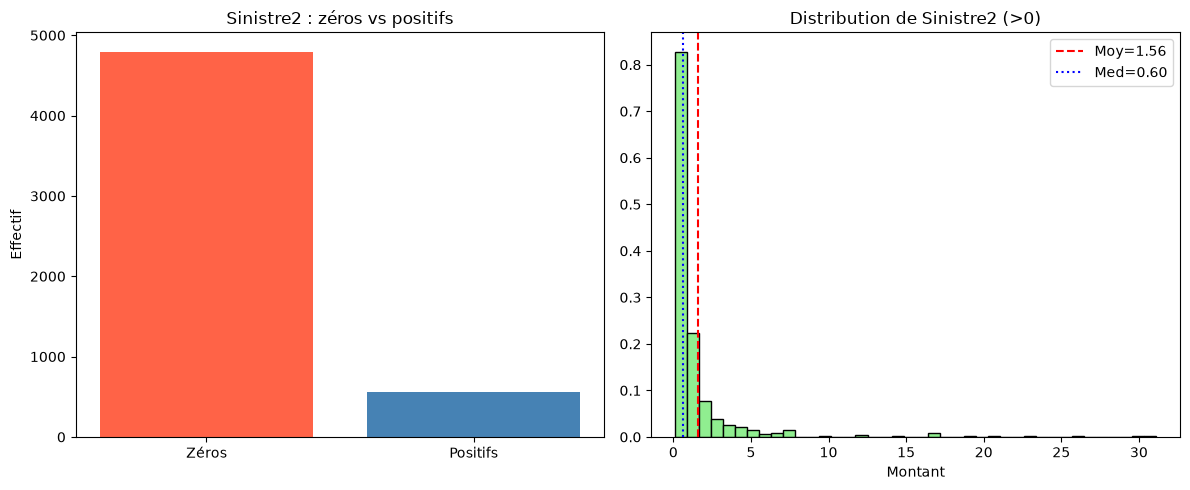

In [35]:
# Comparaison des 3 sinistres partiels — proportion de zéros
for nom in ["Sinistre1", "Sinistre2", "Sinistre3"]:
    n_zero = (dat_pos[nom] == 0).sum()
    n_pos = (dat_pos[nom] > 0).sum()
    pct_zero = n_zero / len(dat_pos) * 100
    print(f"{nom}: {pct_zero:.2f}% de zéros (N=0: {n_zero}, N>0: {n_pos})")


# Statistiques descriptives de Sinistre2 (variable retenue)
s2 = dat_pos["Sinistre2"]
s2_pos = s2[s2 > 0]

print(f"\nN observations : {len(s2)}")
print(f"N = 0 (censurés) : {(s2 == 0).sum()} ({(s2==0).mean()*100:.2f}%)")
print(f"N > 0 (non censurés) : {(s2 > 0).sum()} ({(s2>0).mean()*100:.2f}%)")
print(f"Moyenne totale : {s2.mean():.4f}")
print(f"Médiane totale : {s2.median():.4f}")
print(f"Écart-type total : {s2.std():.4f}")
print(f"Moyenne (y>0) : {s2_pos.mean():.4f}")
print(f"Médiane (y>0) : {s2_pos.median():.4f}")
print(f"Maximum : {s2.max():.2f}")


# Visualisation : zéros vs positifs, et densité des positifs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(["Zéros", "Positifs"], [(s2==0).sum(), (s2>0).sum()],
            color=["tomato", "steelblue"])
axes[0].set_title("Sinistre2 : zéros vs positifs")
axes[0].set_ylabel("Effectif")

axes[1].hist(s2_pos, bins=40, density=True, color="lightgreen", edgecolor="black")
axes[1].axvline(s2_pos.mean(), color="red", linestyle="--", label=f"Moy={s2_pos.mean():.2f}")
axes[1].axvline(s2_pos.median(), color="blue", linestyle=":", label=f"Med={s2_pos.median():.2f}")
axes[1].set_title("Distribution de Sinistre2 (>0)")
axes[1].set_xlabel("Montant")
axes[1].legend()

plt.tight_layout()
plt.show()

**Choix de la variable de réponse : `Sinistre2`.**
`Sinistre2` présente 89,63 % de zéros, contre 76,33 % et 33,26 % pour les deux autres variables de sinistre. C'est donc celle où la masse en zéro est la plus marquée, ce qui justifie une modélisation en deux composantes (survenance, puis montant). Seuls 555 foyers sur 5 352 ont un montant strictement positif. Ces montants sont très asymétriques : moyenne 1,56 pour une médiane de 0,60, maximum 31,10.

### Étape 2 — Spécification du modèle Tobit

Le modèle Tobit de type I suppose une variable latente

y* = Xβ + ε, ε ~ N(0, σ²),

et l'on observe y = max(0, y*). La vraisemblance comporte deux contributions :

- observation censurée (y = 0) : P(y* ≤ 0) = Φ(−Xβ/σ) ;
- observation positive (y > 0) : densité normale de y*, soit (1/σ)·φ((y − Xβ)/σ).

Pour garantir σ > 0, l'optimisation porte sur log σ (σ = exp(log σ)). `statsmodels` n'ayant pas de Tobit natif, le modèle est implémenté à la main par maximum de vraisemblance. Les hypothèses de normalité et d'homoscédasticité de ε, ainsi que le fait qu'un même mécanisme gouverne la survenance et le montant, sont remises en cause plus loin.

In [36]:
# Spécification identique au modèle a priori de la Partie 2, avec Sinistre2 comme réponse.
# RUC est exprimé en dizaines de milliers d'unités pour un bon conditionnement numérique.
y, X_df = patsy.dmatrices(
    "Sinistre2 ~ I(RUC / 10000) + C(pcs) + C(region) + C(Ahabi) + C(Atyph)"
    " + C(agecat) + C(Acompm) + C(Bauto)",
    data=dat_pos,
    return_type="dataframe",
)
noms_var = X_df.columns.tolist()
y = y.values.flatten()
X = X_df.values
n, k = X.shape
print(f"N observations : {n} | N paramètres (dont intercept) : {k}")


def neg_loglik_tobit(params, y, X):
    """Opposé de la log-vraisemblance d'un Tobit de type I censuré à gauche en 0."""
    beta = params[:-1]
    log_sigma = params[-1]
    sigma = np.exp(log_sigma)
    Xb = X @ beta
    censored = (y == 0)

    ll_censored = norm.logcdf(-Xb[censored] / sigma)
    resid = (y[~censored] - Xb[~censored]) / sigma
    ll_uncensored = norm.logpdf(resid) - log_sigma
    return -(ll_censored.sum() + ll_uncensored.sum())


def grad_neg_loglik_tobit(params, y, X):
    """Gradient analytique de neg_loglik_tobit par rapport à (beta, log sigma)."""
    beta = params[:-1]
    sigma = np.exp(params[-1])
    Xb = X @ beta
    cens = (y == 0)

    # Observations censurées : d/dθ log Φ(a), avec a = -Xb/σ
    a = -Xb[cens] / sigma
    lam = np.exp(norm.logpdf(a) - norm.logcdf(a))
    g_beta = -(X[cens].T @ lam) / sigma
    g_logsig = -np.sum(a * lam)

    # Observations positives : densité normale
    r = (y[~cens] - Xb[~cens]) / sigma
    g_beta = g_beta + X[~cens].T @ r / sigma
    g_logsig = g_logsig + np.sum(r**2 - 1)

    return -np.append(g_beta, g_logsig)


# Valeurs initiales : MCO sur y
beta_start, _, _, _ = lstsq(X, y, rcond=None)
sigma_start = (y - X @ beta_start).std()
start_params = np.append(beta_start, np.log(sigma_start))

res_tobit = minimize(
    neg_loglik_tobit, start_params, args=(y, X),
    jac=grad_neg_loglik_tobit,
    method="BFGS", options={"maxiter": 1000},
)

beta_hat = res_tobit.x[:-1]
sigma_hat = np.exp(res_tobit.x[-1])
loglik_tobit = -res_tobit.fun
k_params = len(res_tobit.x)
aic_tobit = -2 * loglik_tobit + 2 * k_params

print(f"Convergence signalée par BFGS : {res_tobit.success}")
print(f"Itérations                    : {res_tobit.nit}")
print(f"Norme du gradient             : {np.linalg.norm(res_tobit.jac):.2e}")
print(f"Log-vraisemblance             : {loglik_tobit:.4f}")
print(f"AIC                           : {aic_tobit:.4f}")
print(f"Sigma estimé                  : {sigma_hat:.4f}")
print(f"Nombre de paramètres          : {k_params} (dont sigma)")

N observations : 5352 | N paramètres (dont intercept) : 29
Convergence signalée par BFGS : True
Itérations                    : 65
Norme du gradient             : 3.68e-06
Log-vraisemblance             : -2664.8244
AIC                           : 5389.6487
Sigma estimé                  : 4.6613
Nombre de paramètres          : 30 (dont sigma)


L'optimisation converge (norme du gradient de 3,7·10⁻⁶, log-vraisemblance de −2 664,82, σ̂ = 4,66). Les erreurs standard sont obtenues en inversant la hessienne numérique au point optimal, dont la plus petite valeur propre est strictement positive (0,078).

In [37]:
# Hessienne numérique du critère, obtenue en dérivant le gradient analytique
hess_fn = nd.Jacobian(lambda p: grad_neg_loglik_tobit(p, y, X))
H = hess_fn(res_tobit.x)
H = (H + H.T) / 2  # symétrisation (bruit numérique)

valeurs_propres = np.linalg.eigvalsh(H)
print(f"Plus petite valeur propre de la hessienne : {valeurs_propres.min():.3e}")
assert valeurs_propres.min() > 0, "Hessienne non définie positive : optimum non atteint"

vcov = np.linalg.inv(H)
se = np.sqrt(np.diag(vcov))

se_beta = se[:-1]
z_stats = beta_hat / se_beta
p_values = 2 * (1 - norm.cdf(np.abs(z_stats)))

# Tableau récapitulatif des coefficients
resultats_tobit = pd.DataFrame({
    "Variable": noms_var,
    "Coef": beta_hat,
    "SE": se_beta,
    "z": z_stats,
    "p_value": p_values,
})
resultats_tobit["signif"] = resultats_tobit["p_value"].apply(
    lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
)
print(resultats_tobit.round(4).to_string(index=False))

# Nombre de coefficients significatifs au seuil de 5 %
n_sig = (resultats_tobit["p_value"] < 0.05).sum()
print(f"\n{n_sig} coefficients significatifs au seuil de 5 % (intercept inclus)")

Plus petite valeur propre de la hessienne : 7.773e-02
                                      Variable     Coef     SE       z  p_value signif
                                     Intercept -10.8054 1.6136 -6.6964   0.0000    ***
       C(pcs)[T.Artisans, comm., chefs d'ent.]   2.0625 1.4058  1.4672   0.1423       
    C(pcs)[T.Autres pers. sans activite prof.]   3.3651 1.3791  2.4401   0.0147      *
C(pcs)[T.Cadres et prof. intellectuelles sup.]   3.1539 1.3013  2.4236   0.0154      *
                            C(pcs)[T.Employes]   3.1108 1.2732  2.4433   0.0146      *
                            C(pcs)[T.Ouvriers]   3.0972 1.2589  2.4602   0.0139      *
          C(pcs)[T.Professions intermediaires]   3.3548 1.2715  2.6385   0.0083     **
                           C(pcs)[T.Retraites]   2.9475 1.3541  2.1767   0.0295      *
                                C(region)[T.2]   0.9851 0.9694  1.0161   0.3096       
                                C(region)[T.3]   0.1732 1.0526  0.1646   0.8

**Lecture des coefficients.** Les coefficients portent sur la variable latente y\*, et non sur le sinistre observé : ce ne sont pas des effets marginaux sur le montant moyen. Ils renseignent le sens et la significativité de chaque variable. Onze coefficients sont significatifs au seuil de 5 % (intercept inclus).

- **Catégorie socio-professionnelle** : six modalités sur sept sont significatives par rapport à la référence (coefficients de 2,9 à 3,4). Seule « Artisans, commerçants, chefs d'entreprise » ne l'est pas (p = 0,14). Les écarts entre modalités sont faibles au regard des erreurs standard (environ 1,3) : le résultat traduit surtout un contraste avec la modalité de référence, plutôt qu'une hiérarchie entre catégories.
- **Zone géographique** : région 8 (+2,70, p = 0,005), région 9 (+3,37, p < 0,001) et taille d'agglomération « Paris + agglomération » (+2,87, p = 0,004).
- **Composition du ménage** : « Personne seule » est associée à un coefficient négatif (−0,98, p = 0,016). Les deux modalités de couple sont proches du seuil (p = 0,052 et 0,074).
- **Revenu et équipement** : `RUC` (+0,40 par tranche de 10 000 unités, p = 0,26) et l'absence de véhicule (p = 0,67) ne sont pas significatifs.

### Étape 3 — Du Tobit simple au modèle de sélection (Tobit de type II, Heckman)

Le Tobit simple (de type I) suppose qu'un seul et même processus latent gouverne à la fois la décision de déclarer un sinistre et son montant. Les variables qui influencent « y a-t-il un sinistre ? » et « quel est le montant ? » ont alors les mêmes coefficients, à un facteur d'échelle σ près, ce qui est une hypothèse très rigide.

Le Tobit généralisé (type II) lève cette contrainte en séparant deux équations :

- **sélection** : d\* = Zγ + u, avec d = 1 (sinistre déclaré) si d\* > 0, et 0 sinon ;
- **résultat** : y\* = Xβ + ε, observé seulement si d = 1.

Les erreurs u et ε peuvent être corrélées (coefficient ρ). Cela permet de représenter des ménages dont la probabilité de déclarer est plus élevée et dont les sinistres sont plus (ou moins) coûteux, pour des raisons non observées : c'est le biais de sélection étudié par Heckman.

**Estimation en deux étapes (Heckman).**

1. Probit sur la variable binaire « sinistre déclaré » (d = 1 si `Sinistre2` > 0).
2. Calcul du ratio de Mills inverse λᵢ = φ(Zᵢγ̂) / Φ(Zᵢγ̂).
3. Régression par MCO du montant sur le sous-échantillon des sinistrés (`Sinistre2` > 0), avec λ comme régresseur supplémentaire. Un coefficient de λ significatif indique ρ ≠ 0, donc un biais de sélection.

Deux limites sont à garder en tête. D'une part, les erreurs standard MCO de l'étape 3 ne tiennent pas compte du fait que λ est estimé : le test sur λ est indicatif. D'autre part, les équations de sélection et de résultat utilisent les mêmes variables, sans variable d'exclusion : l'identification repose alors sur la seule non-linéarité de λ, qui peut être très corrélé aux autres régresseurs.

In [38]:
# Variable binaire : sinistre déclaré (1) ou non (0)
dat_pos = dat_pos.assign(declare=(dat_pos["Sinistre2"] > 0).astype(int))
print(dat_pos["declare"].value_counts())

# Étape 1 du Heckman : équation de sélection (probit)
# Mêmes variables explicatives que le Tobit
formule_selection = (
    "declare ~ I(RUC / 10000) + C(pcs) + C(region) + C(Ahabi) + C(Atyph)"
    " + C(agecat) + C(Acompm) + C(Bauto)"
)
mod_probit = smf.probit(formule_selection, data=dat_pos).fit(disp=False)
print(mod_probit.summary())

declare
0    4797
1     555
Name: count, dtype: int64
                          Probit Regression Results                           
Dep. Variable:                declare   No. Observations:                 5352
Model:                         Probit   Df Residuals:                     5323
Method:                           MLE   Df Model:                           28
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.03952
Time:                        16:49:11   Log-Likelihood:                -1712.5
converged:                       True   LL-Null:                       -1782.9
Covariance Type:            nonrobust   LLR p-value:                 5.173e-17
                                                     coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                         -2.1721      0.330     -6.575     

Le probit de sélection est globalement significatif (test du rapport de vraisemblance : p = 5,2·10⁻¹⁷), mais son pouvoir explicatif reste faible (pseudo-R² de McFadden de 0,040). La survenance d'un sinistre est associée de façon significative :

- à la catégorie socio-professionnelle (cinq modalités sur sept, avec des coefficients de 0,67 à 0,77 ; « Retraités » est à la limite, p = 0,053) ;
- à la zone géographique : régions 4 (p = 0,047), 8 (p = 0,008) et 9 (p < 0,001), et taille d'agglomération « Paris + agglomération » (+0,55, p = 0,008) ;
- à la composition du ménage : les couples avec enfant(s) (−0,21, p = 0,004) et les personnes seules (−0,25, p = 0,005) déclarent moins souvent un sinistre.

Le revenu (`RUC`, p = 0,16) et l'absence de véhicule (p = 0,79) ne sont pas significatifs.

In [39]:
# Ratio de Mills inverse : λ = φ(Zγ) / Φ(Zγ), où Zγ est l'indice linéaire du probit
Zg_hat = mod_probit.fittedvalues
dat_pos["mills_ratio"] = norm.pdf(Zg_hat) / norm.cdf(Zg_hat)
print(dat_pos["mills_ratio"].describe().round(3))

# Étape 2 : MCO du montant sur le sous-échantillon des sinistrés, avec λ
dat_declare = dat_pos[dat_pos["declare"] == 1].copy()

regresseurs = (
    "I(RUC / 10000) + C(pcs) + C(region) + C(Ahabi) + C(Atyph)"
    " + C(agecat) + C(Acompm) + C(Bauto)"
)
mod_heckman = smf.ols(
    f"Sinistre2 ~ {regresseurs} + mills_ratio", data=dat_declare
).fit(cov_type="HC1")
print(mod_heckman.summary())

# Colinéarité de λ avec les régresseurs (sous-échantillon des sinistrés)
aux = smf.ols(f"mills_ratio ~ {regresseurs}", data=dat_declare).fit()
print(f"\nR² de λ sur les régresseurs : {aux.rsquared:.3f}")

count    5352.000
mean        1.784
std         0.240
min         1.175
25%         1.602
50%         1.785
75%         1.953
max         2.875
Name: mills_ratio, dtype: float64
                            OLS Regression Results                            
Dep. Variable:              Sinistre2   R-squared:                       0.060
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     2.029
Date:                Wed, 14 Oct 2026   Prob (F-statistic):            0.00136
Time:                        16:49:11   Log-Likelihood:                -1425.0
No. Observations:                 555   AIC:                             2910.
Df Residuals:                     525   BIC:                             3040.
Df Model:                          29                                         
Covariance Type:                  HC1                                         
                                

Le ratio de Mills inverse varie de 1,18 à 2,88 (moyenne 1,78, écart-type 0,24). Sa faible dispersion annonce une forte dépendance vis-à-vis des autres régresseurs : le R² de λ sur ces variables est de 1,000 (arrondi à trois décimales), ce qui limite fortement la précision du coefficient de λ.

**Résultat du test de sélection.** Le coefficient du ratio de Mills est de 15,5 (erreur standard 47,3 ; p = 0,74) : l'hypothèse de non-corrélation entre les deux équations (ρ = 0) n'est pas rejetée. Aucun coefficient de la régression n'est significatif au seuil de 5 % (plus petite p-value : 0,19) et le pouvoir explicatif est quasi nul (R² = 0,060 ; R² ajusté = 0,008).

**Ce résultat ne permet pas de conclure à l'absence de biais de sélection.** Les équations de sélection et de montant reposent sur les mêmes variables, sans variable d'exclusion : le ratio de Mills est quasi parfaitement expliqué par ces variables (R² ≈ 1,000). Le coefficient de λ n'est donc pas identifié de façon utile : son intervalle de confiance à 95 % ([−77 ; +108]) est très large au regard de l'échelle des montants (moyenne des sinistres positifs : 1,56), et les coefficients des autres variables sont eux aussi instables (erreurs standard très élevées). La non-significativité traduit un manque d'information plutôt qu'une absence de corrélation entre les deux mécanismes.

Elle reste compatible avec une modélisation à deux composantes indépendantes (Double-Hurdle), sans que le Heckman la démontre : un modèle de sélection fiable exigerait une variable influençant la survenance sans influencer le montant, absente ici.

### Étape 4 — Modèle à deux composantes indépendantes (Double-Hurdle)

Les deux équations sont estimées séparément, en supposant les erreurs indépendantes (ρ = 0), donc sans ratio de Mills :

- **survenance** : le probit déjà estimé (`mod_probit`) ;
- **montant** : régression par MCO de log(`Sinistre2`) sur le sous-échantillon des sinistrés, ce qui revient à supposer des montants log-normaux.

Sous l'hypothèse d'indépendance, la log-vraisemblance totale est la somme des deux : LL = LL_probit + LL_log-normale. Contrairement au Tobit, les deux mécanismes disposent de paramètres distincts.

In [40]:
# Équation de montant : log(Sinistre2) sur le sous-échantillon des sinistrés, sans ratio de Mills
formule_montant = f"np.log(Sinistre2) ~ {regresseurs}"
mod_montant = smf.ols(formule_montant, data=dat_declare).fit(cov_type="HC1")
print(mod_montant.summary())

                            OLS Regression Results                            
Dep. Variable:      np.log(Sinistre2)   R-squared:                       0.083
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     2.835
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.83e-06
Time:                        16:49:11   Log-Likelihood:                -760.78
No. Observations:                 555   AIC:                             1580.
Df Residuals:                     526   BIC:                             1705.
Df Model:                          28                                         
Covariance Type:                  HC1                                         
                                                     coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

**Lecture de l'équation de montant.** Sur les 555 foyers sinistrés, le modèle explique peu de variance (R² = 0,083 ; R² ajusté = 0,035) mais il est globalement significatif (test de Wald robuste : p = 2,8·10⁻⁶). Un coefficient β se lit comme un effet multiplicatif exp(β) sur le montant médian d'un sinistre, une fois le sinistre survenu :

- **catégorie socio-professionnelle** : les sept modalités sont significatives par rapport à la référence (de +0,70 à +1,29), avec le coefficient le plus élevé pour les « Retraités » (+1,29, soit un montant multiplié par 3,6) ;
- **zone géographique** : les sept régions sont significatives, et la taille d'agglomération « Paris + agglomération » fait ressortir le coefficient le plus net (+0,91, soit un montant multiplié par 2,5 ; p < 0,001) ;
- **âge** : seule la tranche 51-60 ans est significative (+0,31, p = 0,024) ;
- **composition du ménage, revenu et équipement** : non significatifs (`RUC` : −0,15 par tranche de 10 000 unités, p = 0,29).

Les profils qui influencent la survenance (probit) et le montant ne sont donc pas les mêmes : la composition du ménage joue sur la survenance mais pas sur le montant. C'est précisément ce que le Tobit, qui impose les mêmes coefficients aux deux mécanismes, ne peut pas représenter.

Les résidus du modèle sur log(y) présentent une asymétrie positive (skewness de 0,90 ; test de Jarque-Bera : p < 0,001) : l'hypothèse de log-normalité n'est qu'approximative.

#### Vraisemblance totale du Double-Hurdle

In [41]:
# Log-vraisemblance du Double-Hurdle = LL probit + LL log-normale
ll_probit = mod_probit.llf

# mod_montant.llf est la log-vraisemblance de log(y). Pour obtenir celle de y (comparable
# à celle du Tobit), on retranche le jacobien Σ log(y_i) sur les sinistrés.
ll_lognormal_logy = mod_montant.llf
jacobien = np.log(dat_declare["Sinistre2"]).sum()
ll_lognormal = ll_lognormal_logy - jacobien

ll_double_hurdle = ll_probit + ll_lognormal

k_probit = len(mod_probit.params)
k_lognormal = len(mod_montant.params) + 1  # +1 : variance résiduelle
k_total = k_probit + k_lognormal

aic_double_hurdle = -2 * ll_double_hurdle + 2 * k_total

print(f"LL probit                         : {ll_probit:.4f}")
print(f"LL log-normale (échelle de log y) : {ll_lognormal_logy:.4f}")
print(f"Jacobien Σ log(y)                 : {jacobien:.4f}")
print(f"LL log-normale (échelle de y)     : {ll_lognormal:.4f}")
print(f"LL Double-Hurdle (total)          : {ll_double_hurdle:.4f}")
print(f"Nombre de paramètres              : {k_total}")
print(f"AIC Double-Hurdle                 : {aic_double_hurdle:.4f}")

LL probit                         : -1712.4815
LL log-normale (échelle de log y) : -760.7846
Jacobien Σ log(y)                 : -141.0617
LL log-normale (échelle de y)     : -619.7228
LL Double-Hurdle (total)          : -2332.2043
Nombre de paramètres              : 59
AIC Double-Hurdle                 : 4782.4086


### Étape 5 — Comparaison Tobit / Double-Hurdle

In [42]:
n_obs = len(dat_pos)
bic_tobit = -2 * loglik_tobit + k_params * np.log(n_obs)
bic_double_hurdle = -2 * ll_double_hurdle + k_total * np.log(n_obs)

comparaison = pd.DataFrame(
    {
        "Log-vraisemblance": [loglik_tobit, ll_double_hurdle],
        "Paramètres": [k_params, k_total],
        "AIC": [aic_tobit, aic_double_hurdle],
        "BIC": [bic_tobit, bic_double_hurdle],
    },
    index=["Tobit", "Double-Hurdle"],
).round(2)
display(comparaison)

,Log-vraisemblance,Paramètres,AIC,BIC
Tobit,-2664.82,30,5389.65,5587.21
Double-Hurdle,-2332.20,59,4782.41,5170.94


Le Tobit (partie positive normale en niveau) et le Double-Hurdle (partie positive log-normale) ne sont pas emboîtés : un test du rapport de vraisemblance n'est donc pas applicable, et la comparaison repose sur les critères d'information AIC et BIC, calculés sur la même échelle (densité de y, jacobien inclus).

**Lecture de la comparaison.** Le Double-Hurdle est nettement préféré : sa log-vraisemblance est supérieure de 333 points (−2 332,20 contre −2 664,82), et ses critères d'information sont plus bas malgré 29 paramètres supplémentaires (AIC : 4 782,41 contre 5 389,65, soit −607 ; BIC : 5 170,94 contre 5 587,21, soit −416). Le BIC, qui pénalise davantage la complexité, conduit à la même conclusion. Ces critères sont calculés sur l'échantillon d'estimation.

### Bilan de la Partie 3

- **Tobit (type I)** : un seul mécanisme latent gouverne survenance et montant. Estimé par maximum de vraisemblance (convergence vérifiée, norme du gradient de 3,7·10⁻⁶, σ̂ = 4,66), il ne met en évidence que 11 coefficients significatifs, et suppose une partie positive normale en niveau, peu adaptée à des montants très asymétriques (moyenne de 1,56 pour une médiane de 0,60).
- **Heckman (type II)** : le test de sélection est non concluant (coefficient de λ non significatif, p = 0,74, mais λ quasi parfaitement colinéaire avec les régresseurs : R² ≈ 1,000). Faute de variable d'exclusion, il ne permet ni de conclure à l'absence de corrélation entre les deux mécanismes, ni de la mettre en évidence.
- **Double-Hurdle** : probit pour la survenance et modèle log-normal pour le montant, indépendants par hypothèse. Il est préféré au Tobit selon l'AIC et le BIC (écart de 607 et 416 points). Les facteurs de survenance et de montant diffèrent en partie (la composition du ménage joue sur la survenance seule), ce que le Tobit ne peut pas représenter.

**Limites** : l'indépendance entre survenance et montant est supposée et n'a pas pu être testée de façon fiable ; la log-normalité du montant est approximative (asymétrie résiduelle) ; la comparaison repose sur des critères calculés en échantillon.

## Partie 4 — Modélisation du nombre de sinistres (NSin)

Comme pour le modèle a priori de la Partie 2, seules les variables sociodémographiques du ménage servent de variables explicatives : les variables a posteriori (`Police1` à `Police3`) sont exclues, de même que la durée de souscription `Duree`, utilisée ni comme variable explicative ni comme offset. L'hétérogénéité de souscription entre foyers n'est donc pas modélisée et peut contribuer à la surdispersion.

**Cadre théorique.** `NSin` est une variable de comptage (entier ≥ 0), pour laquelle le cadre naturel est le modèle de Poisson. Celui-ci impose toutefois l'égalité de la moyenne et de la variance, alors que la Partie 1 a mis en évidence une surdispersion (variance/moyenne = 3,419). La binomiale négative, qui relâche cette contrainte par un paramètre de dispersion supplémentaire, est donc l'alternative attendue.

### Étape 1 — Modèle de Poisson (mesure de la surdispersion)

In [43]:
# Spécification identique à celle des Parties 2 et 3 (variables sociodémographiques uniquement)
formule_nsin = f"NSin ~ {regresseurs}"

mod_poisson = smf.glm(
    formule_nsin, data=dat_pos, family=sm.families.Poisson()
).fit()
print(mod_poisson.summary())

# Diagnostic de surdispersion : statistique de Pearson / degrés de liberté résiduels
pearson_chi2 = mod_poisson.pearson_chi2
ddl_resid = mod_poisson.df_resid
dispersion = pearson_chi2 / ddl_resid

print(f"\nPearson chi2         : {pearson_chi2:.2f}")
print(f"Ddl résiduels        : {ddl_resid:.0f}")
print(f"Ratio de dispersion  : {dispersion:.4f}")
print("(1 = Poisson adapté ; nettement > 1 = surdispersion)")

                 Generalized Linear Model Regression Results                  
Dep. Variable:                   NSin   No. Observations:                 5352
Model:                            GLM   Df Residuals:                     5323
Model Family:                 Poisson   Df Model:                           28
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -14857.
Date:                Wed, 14 Oct 2026   Deviance:                       15919.
Time:                        16:49:11   Pearson chi2:                 1.34e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.5561
Covariance Type:            nonrobust                                         
                                                     coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------

Le ratio de dispersion de Pearson est de 2,52 (χ² = 13 427 pour 5 323 degrés de liberté) : la variance résiduelle est environ deux fois et demie supérieure à ce que suppose le Poisson. Ce diagnostic, calculé après prise en compte des variables explicatives, confirme la surdispersion observée sur la variable brute (variance/moyenne = 3,419, Partie 1). Les coefficients du Poisson restent convergents si l'espérance est correctement spécifiée, mais leurs erreurs standard sont sous-estimées : leur significativité n'est donc pas interprétée ici, et le modèle est étendu à la binomiale négative.

### Étape 2 — Modèle binomial négatif

La binomiale négative (NB2) ajoute un paramètre de dispersion α, estimé par maximum de vraisemblance en même temps que les coefficients : Var(Y) = μ + α·μ², contre Var(Y) = μ pour Poisson, qui correspond à α = 0.

In [44]:
y_nsin, X_nsin = patsy.dmatrices(formule_nsin, data=dat_pos, return_type="dataframe")

mod_nb = NegativeBinomial(y_nsin, X_nsin).fit(disp=False, maxiter=200)
print(mod_nb.summary())
print(f"\nConvergence : {mod_nb.mle_retvals['converged']}")

print(f"Alpha (dispersion) estimé : {mod_nb.params['alpha']:.4f}")
print(f"P-value de alpha (Wald)   : {mod_nb.pvalues['alpha']:.4e}")
print(f"LogLik Poisson            : {mod_poisson.llf:.4f} | AIC : {mod_poisson.aic:.4f}")
print(f"LogLik Binomiale Négative : {mod_nb.llf:.4f} | AIC : {mod_nb.aic:.4f}")

                     NegativeBinomial Regression Results                      
Dep. Variable:                   NSin   No. Observations:                 5352
Model:               NegativeBinomial   Df Residuals:                     5323
Method:                           MLE   Df Model:                           28
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                 0.04596
Time:                        16:49:11   Log-Likelihood:                -13034.
converged:                       True   LL-Null:                       -13662.
Covariance Type:            nonrobust   LLR p-value:                7.596e-247
                                                     coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                          1.5181      0.124     12.216      0.000       1.275       1.762
C(pcs)[T.Artisans, comm

**Choix de l'échelle de `RUC`.** Le revenu est exprimé en dizaines de milliers d'unités (`I(RUC / 10000)`), comme dans les Parties 2 et 3. Sur l'échelle brute, l'optimisation de la binomiale négative ne converge pas (messages d'overflow).

**Dispersion.** Le paramètre de dispersion est estimé à α = 0,53 (erreur standard 0,019 ; p < 10⁻¹⁷⁰ au test de Wald), donc Var(Y) = μ + 0,53·μ². L'hypothèse α = 0 (Poisson) est nettement rejetée : la log-vraisemblance passe de −14 856,85 (Poisson) à −13 034,02 (NB), soit une statistique de rapport de vraisemblance de 3 645,7, et l'AIC de 29 771,71 à 26 128,04. Comme α = 0 se situe en bordure de l'espace des paramètres, ce test n'a pas la loi usuelle du χ², mais l'écart est sans commune mesure avec ce seuil.

**Lecture des coefficients** (effets multiplicatifs exp(β) sur le nombre moyen de sinistres) :

- **composition du ménage** : c'est l'effet le plus marqué. Une personne seule a un nombre de sinistres espéré multiplié par 0,32 (β = −1,14 ; p < 0,001) et un couple sans enfant par 0,61 (β = −0,49 ; p < 0,001), par rapport à la modalité de référence ;
- **âge** : les 51-60 ans (×0,87 ; p = 0,002) et les 61-96 ans (×0,80 ; p = 0,003) déclarent moins de sinistres ;
- **revenu et équipement** : `RUC` (×0,85 par tranche de 10 000 unités ; p < 0,001) et l'absence de véhicule (×0,88 ; p = 0,022) sont associés à une fréquence plus faible ;
- **catégorie socio-professionnelle** : « Cadres » (×1,36 ; p = 0,001), « Professions intermédiaires » (×1,32 ; p = 0,002), « Employés » (p = 0,029) et « Ouvriers » (p = 0,030) ont une fréquence plus élevée que la référence ;
- **zone géographique** : seule la région 9 est significative (×1,29 ; p = 0,006).

Par rapport au Poisson, les erreurs standard de la NB sont nettement plus grandes (par exemple pour « Paris + agglomération » : p = 0,046 en Poisson contre 0,109 en NB) : le Poisson surestimait la significativité de plusieurs variables.

### Étape 3 — Vérification de l'excès de zéros

Il s'agit de vérifier si `NSin` présente plus de zéros que ne le prévoit la binomiale négative, ce qui justifierait un modèle à inflation de zéros (ZINB).

In [45]:
pct_zero_nsin = (dat_pos["NSin"] == 0).mean() * 100
print(f"% de zéros dans NSin : {pct_zero_nsin:.2f}%")
print(dat_pos["NSin"].value_counts().sort_index().head(12))

% de zéros dans NSin : 26.01%
NSin
0     1392
2      308
3      741
4      654
5      668
6      639
7       85
8      200
9       57
10     272
12     173
14      38
Name: count, dtype: int64


**Régularité de la distribution de `NSin`.**

In [46]:
print(f"Nombre de ménages avec NSin = 1 : {(dat_pos['NSin'] == 1).sum()}")
print("Valeurs distinctes de NSin :", sorted(dat_pos["NSin"].unique().tolist()))

Nombre de ménages avec NSin = 1 : 0
Valeurs distinctes de NSin : [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 15, 16, 18, 20, 21, 22, 24, 30]


**Structure de la distribution.** Aucun foyer n'a exactement un sinistre (`NSin` = 1), et les valeurs 11 et 13 sont également absentes ; les effectifs sont irréguliers (308 foyers à 2 sinistres, 741 à 3). La distribution présente donc des irrégularités qu'aucune loi de comptage usuelle ne peut reproduire exactement (jeu de données fictif).

In [47]:
mu_hat = np.asarray(mod_nb.predict())
alpha_hat = mod_nb.params["alpha"]
r = 1 / alpha_hat

proba_zero_predite = nbinom.pmf(0, r, r / (r + mu_hat)).mean()
proba_zero_observee = (dat_pos["NSin"] == 0).mean()

print(f"Proportion de zéros observée         : {proba_zero_observee:.4f}")
print(f"Proportion de zéros prédite par la NB : {proba_zero_predite:.4f}")

Proportion de zéros observée         : 0.2601
Proportion de zéros prédite par la NB : 0.1444


La binomiale négative prédit 14,4 % de zéros contre 26,0 % observés : elle sous-estime nettement les foyers sans sinistre. Cet écart est compatible avec une inflation de zéros, mais il ne suffit pas à l'établir, car la distribution est irrégulière par ailleurs (voir ci-dessus). Un modèle à inflation de zéros est donc estimé pour vérifier si cet écart est réduit.

### Étape 4 — Binomiale négative à inflation de zéros (ZINB)

Le ZINB mélange deux populations :

- avec une probabilité π, un « zéro structurel » (foyer qui ne peut pas déclarer de sinistre, par exemple faute de garantie) ;
- avec une probabilité 1 − π, un nombre de sinistres suivant la binomiale négative, qui peut aussi valoir 0 « par hasard ».

Ainsi P(Y = 0) = π + (1 − π)·f(0) et P(Y = y) = (1 − π)·f(y) pour y > 0, où f est la loi binomiale négative. Ici π est constant (logit sur une constante) et la partie comptage reprend les variables de la NB. Contrairement au Double-Hurdle de la Partie 3, où un zéro n'a qu'une seule origine (pas de sinistre déclaré), les zéros proviennent ici de deux mécanismes.

Le ZINB de `statsmodels` diverge sur ces données (paramètre de dispersion négatif, résultats non définis). Le modèle est donc estimé par maximum de vraisemblance, avec log α comme paramètre, un gradient analytique et des valeurs initiales issues de la NB et de l'excès de zéros observé.

In [48]:
def _logf_nb2(params, y, X):
    """Quantités communes : γ0, moyennes μ, r = 1/α et log f_NB2(y ; μ, α)."""
    gamma0 = params[0]
    beta = params[1:-1]
    alpha = np.exp(params[-1])
    mu = np.exp(np.clip(X @ beta, -30, 30))
    r = 1.0 / alpha
    logf = (gammaln(y + r) - gammaln(r) - gammaln(y + 1)
            + r * np.log(r / (r + mu)) + y * np.log(mu / (r + mu)))
    return gamma0, mu, r, logf


def neg_loglik_zinb(params, y, X):
    """Opposé de la log-vraisemblance du ZINB (π constant ; params = [γ0, β, log α])."""
    gamma0, mu, r, logf = _logf_nb2(params, y, X)
    log_pi, log_1mpi = log_expit(gamma0), log_expit(-gamma0)
    ll = np.where(y == 0,
                  np.logaddexp(log_pi, log_1mpi + logf),
                  log_1mpi + logf)
    return -ll.sum()


def grad_neg_loglik_zinb(params, y, X):
    """Gradient analytique de neg_loglik_zinb."""
    gamma0, mu, r, logf = _logf_nb2(params, y, X)
    pi = expit(gamma0)
    zero = (y == 0)
    f = np.exp(logf)
    P0 = pi + (1 - pi) * f
    w = np.where(zero, (1 - pi) * f / P0, 1.0)  # poids de la composante comptage

    dlogf_deta = (y - mu) / (1 + mu / r)
    dlogf_dr = (digamma(y + r) - digamma(r) + np.log(r / (r + mu))
                + 1 - (r + y) / (r + mu))
    dlogf_dlogalpha = -r * dlogf_dr

    g_gamma = np.where(zero, pi * (1 - pi) * (1 - f) / P0, -pi).sum()
    g_beta = X.T @ (w * dlogf_deta)
    g_logalpha = (w * dlogf_dlogalpha).sum()
    return -np.concatenate(([g_gamma], g_beta, [g_logalpha]))


y_arr = y_nsin.to_numpy().ravel().astype(float)
X_arr = X_nsin.to_numpy()

# Valeurs initiales : coefficients et dispersion de la NB ; π issu de l'excès de zéros observé
beta_nb = mod_nb.params.drop("alpha").to_numpy()
alpha_nb = mod_nb.params["alpha"]
pi_start = (proba_zero_observee - proba_zero_predite) / (1 - proba_zero_predite)
start_zinb = np.concatenate(([np.log(pi_start / (1 - pi_start))], beta_nb, [np.log(alpha_nb)]))

# Contrôle : avec π ≈ 0, la log-vraisemblance du ZINB doit retrouver celle de la NB
controle = -neg_loglik_zinb(
    np.concatenate(([-30.0], beta_nb, [np.log(alpha_nb)])), y_arr, X_arr
)
print(f"Contrôle : LL(ZINB, π≈0) = {controle:.4f} | LL(NB) = {mod_nb.llf:.4f}")

res_zinb = minimize(
    neg_loglik_zinb, start_zinb, args=(y_arr, X_arr),
    jac=grad_neg_loglik_zinb, method="BFGS", options={"maxiter": 1000},
)

gamma0_z, beta_z, alpha_z = res_zinb.x[0], res_zinb.x[1:-1], np.exp(res_zinb.x[-1])
pi_z = expit(gamma0_z)
loglik_zinb = -res_zinb.fun
k_zinb = len(res_zinb.x)
aic_zinb = -2 * loglik_zinb + 2 * k_zinb

print(f"Convergence signalée par BFGS : {res_zinb.success}")
print(f"Itérations                    : {res_zinb.nit}")
print(f"Norme du gradient             : {np.linalg.norm(res_zinb.jac):.2e}")
print(f"Log-vraisemblance ZINB        : {loglik_zinb:.4f}")
print(f"π estimé (zéros structurels)  : {pi_z:.4f}")
print(f"α estimé                      : {alpha_z:.4f}")
print(f"Nombre de paramètres          : {k_zinb}")

Contrôle : LL(ZINB, π≈0) = -13034.0191 | LL(NB) = -13034.0191
Convergence signalée par BFGS : False
Itérations                    : 47
Norme du gradient             : 4.91e-05
Log-vraisemblance ZINB        : -11945.0858
π estimé (zéros structurels)  : 0.2289
α estimé                      : 0.0595
Nombre de paramètres          : 31


BFGS signale une convergence formelle non atteinte (perte de précision de la recherche linéaire), mais la norme du gradient est de 4,9·10⁻⁵, la hessienne est définie positive et le contrôle avec π ≈ 0 retrouve exactement la log-vraisemblance de la NB : les estimations sont retenues. Les erreurs standard sont obtenues en inversant la hessienne numérique au point optimal.

In [49]:
# Erreurs standard : hessienne numérique obtenue en dérivant le gradient analytique
hess_zinb = nd.Jacobian(lambda p: grad_neg_loglik_zinb(p, y_arr, X_arr))
H_z = hess_zinb(res_zinb.x)
H_z = (H_z + H_z.T) / 2
assert np.linalg.eigvalsh(H_z).min() > 0, "Hessienne non définie positive"
se_z = np.sqrt(np.diag(np.linalg.inv(H_z)))

noms = ["inflation (constante)"] + list(X_nsin.columns) + ["log alpha"]
z_z = res_zinb.x / se_z
tab_zinb = pd.DataFrame({
    "Coef": res_zinb.x, "SE": se_z, "z": z_z,
    "p_value": 2 * (1 - norm.cdf(np.abs(z_z))),
}, index=noms).round(4)
print(tab_zinb.to_string())

print(f"\nπ = {pi_z:.4f} (SE par delta : {pi_z * (1 - pi_z) * se_z[0]:.4f})")
print(f"α = {alpha_z:.4f} (SE par delta : {alpha_z * se_z[-1]:.4f})")

                                                  Coef      SE        z  p_value
inflation (constante)                          -1.2148  0.0358 -33.9712   0.0000
Intercept                                       1.7825  0.0816  21.8521   0.0000
C(pcs)[T.Artisans, comm., chefs d'ent.]         0.1494  0.0687   2.1746   0.0297
C(pcs)[T.Autres pers. sans activite prof.]      0.1487  0.0731   2.0344   0.0419
C(pcs)[T.Cadres et prof. intellectuelles sup.]  0.2651  0.0621   4.2664   0.0000
C(pcs)[T.Employes]                              0.1529  0.0588   2.6024   0.0093
C(pcs)[T.Ouvriers]                              0.1785  0.0567   3.1468   0.0017
C(pcs)[T.Professions intermediaires]            0.2278  0.0584   3.9031   0.0001
C(pcs)[T.Retraites]                             0.1067  0.0713   1.4973   0.1343
C(region)[T.2]                                  0.0576  0.0581   0.9917   0.3214
C(region)[T.3]                                  0.0816  0.0631   1.2930   0.1960
C(region)[T.4]              

**Lecture de la partie comptage du ZINB** (effets multiplicatifs exp(β) sur le nombre moyen de sinistres des foyers hors « zéros structurels ») :

- **composition du ménage** : effet dominant, comme pour la NB. Une personne seule a un nombre moyen de sinistres multiplié par 0,36 (β = −1,03 ; p < 0,001) et un couple sans enfant par 0,65 (β = −0,43 ; p < 0,001) ;
- **revenu** : `RUC` est associé à une fréquence plus faible (×0,80 par tranche de 10 000 unités ; p < 0,001) ;
- **âge** : les 51-60 ans (×0,93 ; p = 0,012) et les 61-96 ans (×0,89 ; p = 0,027) déclarent moins de sinistres ;
- **catégorie socio-professionnelle** : six modalités sur sept sont significatives (de ×1,16 à ×1,30), seule « Retraités » ne l'est pas (p = 0,13) ;
- **zone géographique et logement** : région 9 (×1,21 ; p = 0,002) et statut « Propriétaire » (effet faible : ×1,04 ; p = 0,031) ;
- **équipement** : l'absence de véhicule n'est plus significative (p = 0,50), alors qu'elle l'était dans la NB (p = 0,022) : ce résultat de la NB ne résiste pas à la prise en compte de l'inflation de zéros.

La part estimée de zéros structurels est de π = 0,23 (erreur standard 0,006) et la dispersion de α = 0,06 (erreur standard 0,005).


In [50]:
# Comparaison NB / ZINB
n_obs = len(y_arr)
bic_nb = -2 * mod_nb.llf + len(mod_nb.params) * np.log(n_obs)
bic_zinb = -2 * loglik_zinb + k_zinb * np.log(n_obs)

mu_z = np.exp(X_arr @ beta_z)
r_z = 1 / alpha_z
proba_zero_zinb = pi_z + (1 - pi_z) * nbinom.pmf(0, r_z, r_z / (r_z + mu_z)).mean()

comparaison_nb = pd.DataFrame(
    {
        "Log-vraisemblance": [mod_nb.llf, loglik_zinb],
        "Paramètres": [len(mod_nb.params), k_zinb],
        "AIC": [mod_nb.aic, aic_zinb],
        "BIC": [bic_nb, bic_zinb],
        "P(NSin = 0) prédite": [proba_zero_predite, proba_zero_zinb],
    },
    index=["NB", "ZINB"],
).round(4)
display(comparaison_nb)
print(f"P(NSin = 0) observée : {proba_zero_observee:.4f}")

# Fréquences observées et attendues, pour NSin de 0 à 10
ks = np.arange(0, 11)


def freq_attendue(mu, alpha):
    r = 1 / alpha
    return np.array([nbinom.pmf(k, r, r / (r + mu)).sum() for k in ks])


obs = np.array([(y_arr == k).sum() for k in ks])
att_nb = freq_attendue(mu_hat, alpha_nb)
att_zinb = (1 - pi_z) * freq_attendue(mu_z, alpha_z)
att_zinb[0] += pi_z * n_obs

display(pd.DataFrame({"Observé": obs, "NB": att_nb, "ZINB": att_zinb}, index=ks).round(0).astype(int))

,Log-vraisemblance,Paramètres,AIC,BIC,P(NSin = 0) prédite
NB,-13034.0191,30,26128.0381,26325.5949,0.1444
ZINB,-11945.0858,31,23952.1717,24156.3136,0.2533


P(NSin = 0) observée : 0.2601


,Observé,NB,ZINB
0,1392,773,1356
1,0,841,304
2,308,739,427
3,741,610,486
4,654,492,499
5,668,393,477
6,639,313,431
7,85,249,367
8,200,198,296
9,57,157,227


**Lecture de la comparaison.** Le ZINB est nettement préféré à la NB : sa log-vraisemblance est supérieure de 1 089 points (−11 945,09 contre −13 034,02), son AIC est de 23 952,17 contre 26 128,04 (−2 176) et son BIC de 24 156,31 contre 26 325,59 (−2 169), pour un seul paramètre supplémentaire. La proportion de zéros prédite passe de 14,4 % (NB) à 25,3 % (ZINB), pour 26,0 % observés. Le test du rapport de vraisemblance n'est pas utilisé, car la NB correspond à π = 0, en bordure de l'espace des paramètres.

Le paramètre de dispersion chute de α = 0,53 (NB) à α = 0,06 : l'essentiel de la surdispersion apparente de la NB provenait de l'excès de zéros.

Le tableau des fréquences montre toutefois que l'ajustement reste imparfait. Le ZINB reproduit bien les zéros (1 356 attendus pour 1 392 observés), mais prévoit 304 foyers à un sinistre alors qu'aucun n'est observé, et s'écarte encore sensiblement pour certaines valeurs (7 sinistres : 367 attendus pour 85 observés ; 10 sinistres : 166 pour 272). Ces irrégularités propres au jeu de données (fictif) ne peuvent pas être reproduites par une loi de comptage usuelle. L'interprétation de π comme part de foyers « structurellement » sans sinistre est donc à prendre avec précaution : π absorbe aussi la forme irrégulière de la distribution.

### Bilan de la Partie 4

- **Poisson** : le ratio de dispersion de Pearson (2,52) confirme la surdispersion de `NSin` ; ses erreurs standard sont sous-estimées (AIC : 29 771,71).
- **Binomiale négative** : α = 0,53, AIC de 26 128,04 ; elle sous-estime fortement les zéros (14,4 % prédits pour 26,0 % observés).
- **ZINB (retenu)** : AIC de 23 952,17 et BIC de 24 156,31, soit un gain de plus de 2 100 points sur la NB. Il estime 23 % de zéros structurels et une dispersion résiduelle faible (α = 0,06). Les principaux déterminants de la fréquence sont la composition du ménage, le revenu, l'âge et la catégorie socio-professionnelle.

**Limites** : la durée d'exposition n'est pas modélisée ; la probabilité π est supposée constante (aucune variable dans la partie inflation) ; la distribution de `NSin` est irrégulière (aucun foyer à un sinistre), si bien qu'aucune loi de comptage usuelle ne l'ajuste parfaitement ; le ZINB est estimé à la main, car l'implémentation de `statsmodels` ne converge pas sur ces données.

## Partie 5 — Durée de souscription (fidélité contractuelle) : Kaplan-Meier et Cox

### Étape 1 — Vérification des variables de survie

In [51]:
# Vérification des variables de survie
print(df[["Duree", "censure"]].describe())
print(f"\nRépartition censure : \n{df['censure'].value_counts()}")
print(f"Taux d'événements observés (censure=1) : {df['censure'].mean()*100:.2f}%")

             Duree      censure
count  5352.000000  5352.000000
mean    249.105381     0.617900
std     629.936221     0.485946
min       0.000000     0.000000
25%      23.000000     0.000000
50%      42.500000     1.000000
75%     233.000000     1.000000
max    9877.000000     1.000000

Répartition censure : 
censure
1    3307
0    2045
Name: count, dtype: int64
Taux d'événements observés (censure=1) : 61.79%


La durée `Duree` est très asymétrique (moyenne 249,1 ; médiane 42,5 ; maximum 9 877). Selon le codage de la base, `censure` = 1 correspond à un événement observé (contrat résilié ou non renouvelé pendant la période d'observation) : 3 307 foyers (61,8 %). Les 2 045 autres (38,2 %, `censure` = 0) sont censurés à droite : leur contrat est encore actif en fin d'observation, leur durée réelle est donc supérieure à la durée observée. `lifelines` attend cette même convention (`event_observed` = 1 si l'événement est survenu), qui est celle de la variable `censure`.

### Étape 2 — Courbe de Kaplan-Meier globale

Durée médiane de souscription : 187.00


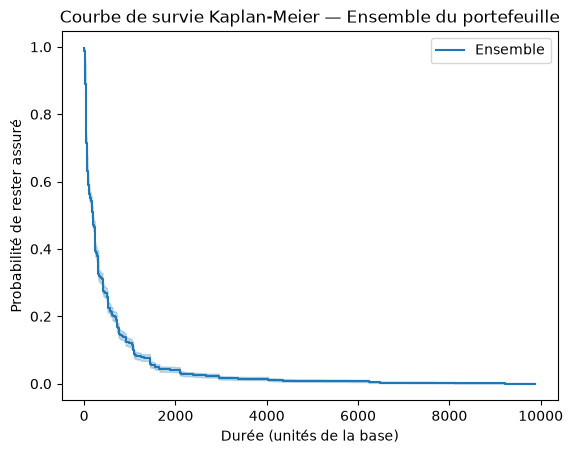

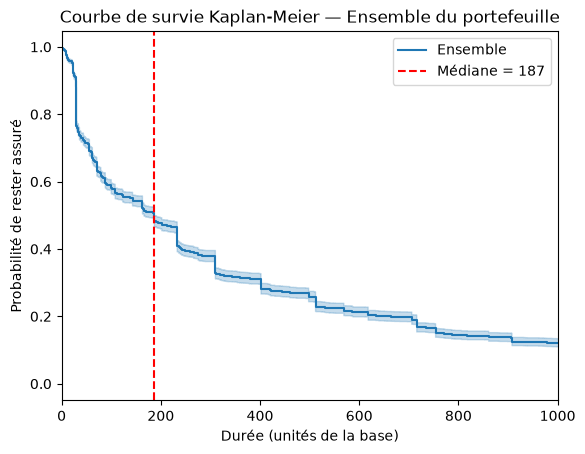

In [52]:
kmf = KaplanMeierFitter()
kmf.fit(durations=df["Duree"], event_observed=df["censure"], label="Ensemble")

print(f"Durée médiane de souscription : {kmf.median_survival_time_:.2f}")

kmf.plot_survival_function()
plt.title("Courbe de survie Kaplan-Meier — Ensemble du portefeuille")
plt.xlabel("Durée (unités de la base)")
plt.ylabel("Probabilité de rester assuré")
plt.show()

kmf.plot_survival_function()
plt.title("Courbe de survie Kaplan-Meier — Ensemble du portefeuille")
plt.xlabel("Durée (unités de la base)")
plt.ylabel("Probabilité de rester assuré")
plt.axvline(kmf.median_survival_time_, color="red", linestyle="--", 
            label=f"Médiane = {kmf.median_survival_time_:.0f}")
plt.xlim(0, 1000)
plt.legend()
plt.show()

La durée médiane de souscription estimée par Kaplan-Meier est de 187 (unités de la base) : la moitié des contrats est rompue avant ce seuil. La courbe chute très rapidement au début, puis s'aplatit : les foyers qui restent assurés au-delà de quelques centaines d'unités le restent longtemps. Contrairement à la médiane brute de `Duree` (42,5), la médiane de Kaplan-Meier tient compte de la censure des contrats encore actifs.

### Étape 3 — Courbes de Kaplan-Meier stratifiées et tests du log-rank

Les courbes sont comparées selon trois critères : taille d'agglomération (`Ahabi`), possession d'un véhicule (`Bauto`) et classe d'âge (`agecat`), avec un test du log-rank pour chacun. Les courbes sont tronquées à une durée de 1 000.

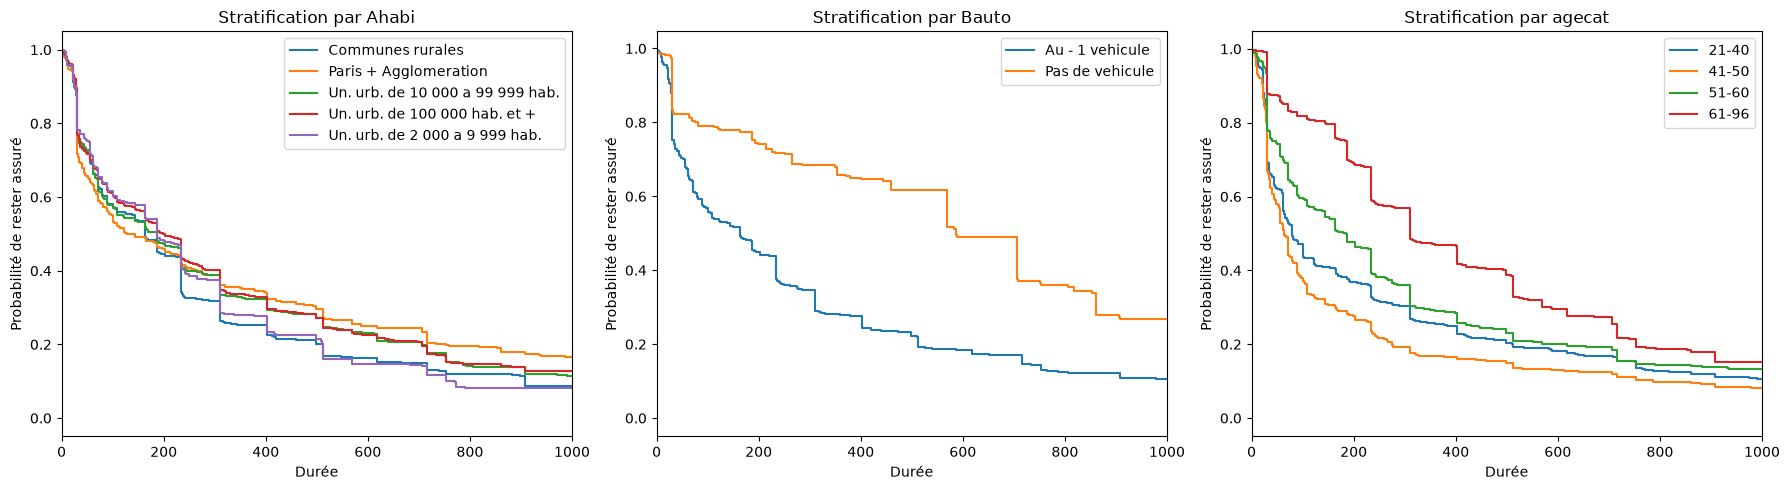

Log-rank Ahabi : stat=14.667, ddl=4, p=5.4442e-03
Log-rank Bauto : stat=93.042, ddl=1, p=5.1204e-22
Log-rank agecat : stat=283.214, ddl=3, p=4.2697e-61


In [53]:
variables_strat = ["Ahabi", "Bauto", "agecat"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for variable, ax in zip(variables_strat, axes):
    for modalite in df[variable].cat.categories:
        masque = df[variable] == modalite
        kmf_strat = KaplanMeierFitter()
        kmf_strat.fit(df.loc[masque, "Duree"], df.loc[masque, "censure"], label=str(modalite))
        kmf_strat.plot_survival_function(ax=ax, ci_show=False)
    ax.set_xlim(0, 1000)
    ax.set_title(f"Stratification par {variable}")
    ax.set_xlabel("Durée")
    ax.set_ylabel("Probabilité de rester assuré")
plt.tight_layout()
plt.show()

# Tests du log-rank (comparaison multi-groupes) pour chaque stratification
for variable in variables_strat:
    result = multivariate_logrank_test(df["Duree"], df[variable], df["censure"])
    print(
        f"Log-rank {variable} : stat={result.test_statistic:.3f}, "
        f"ddl={result.degrees_of_freedom}, p={result.p_value:.4e}"
    )

In [54]:
def table_medianes(variable):
    """Médiane de survie de Kaplan-Meier (avec IC à 95 %) pour chaque modalité."""
    lignes = []
    for modalite in df[variable].cat.categories:
        masque = df[variable] == modalite
        km = KaplanMeierFitter().fit(df.loc[masque, "Duree"], df.loc[masque, "censure"])
        ic = median_survival_times(km.confidence_interval_)
        lignes.append({
            "Modalité": str(modalite),
            "Effectif": int(masque.sum()),
            "Médiane": km.median_survival_time_,
            "IC95 bas": ic.iloc[0, 0],
            "IC95 haut": ic.iloc[0, 1],
        })
    return pd.DataFrame(lignes).set_index("Modalité")


for variable in variables_strat:
    print(f"\n{variable}")
    display(table_medianes(variable))


Ahabi


,Effectif,Médiane,IC95 bas,IC95 haut
Modalité,,,,
Communes rurales,1352,163.0,149.0,187.0
Paris + Agglomeration,697,128.0,100.0,199.0
Un. urb. de 10 000 a 99 999 hab.,1031,187.0,143.0,228.0
Un. urb. de 100 000 hab. et +,1623,200.0,187.0,233.0
Un. urb. de 2 000 a 9 999 hab.,649,187.0,163.0,233.0



Bauto


,Effectif,Médiane,IC95 bas,IC95 haut
Modalité,,,,
Au - 1 vehicule,4909,163.0,153.0,175.0
Pas de vehicule,443,586.0,569.0,706.0



agecat


,Effectif,Médiane,IC95 bas,IC95 haut
Modalité,,,,
21-40,1616,79.0,71.0,100.0
41-50,1483,64.0,56.0,71.0
51-60,854,185.0,163.0,220.0
61-96,1399,310.0,310.0,359.0


**Lecture des trois stratifications.** Les trois critères discriminent significativement la durée de souscription (log-rank : taille d'agglomération p = 0,0054 ; véhicule p = 5,1·10⁻²² ; âge p = 4,3·10⁻⁶¹). Les médianes de Kaplan-Meier, avec leur intervalle de confiance à 95 %, précisent l'ampleur des écarts :

- **Âge** (écart le plus fort, statistique de 283) : la durée médiane est de 79 pour les 21-40 ans, 64 pour les 41-50 ans, 185 pour les 51-60 ans et 310 pour les 61-96 ans. La relation n'est pas monotone : les 41-50 ans sont les moins fidèles, légèrement en dessous des 21-40 ans, puis la rétention augmente nettement à partir de 51 ans.
- **Véhicule** (statistique de 93) : les foyers sans véhicule restent bien plus longtemps (médiane de 586, IC [569 ; 706]) que ceux qui en ont au moins un (163, IC [153 ; 175]), soit environ 3,6 fois plus. Cette modalité est toutefois peu fréquente (443 foyers sur 5 352).
- **Taille d'agglomération** (statistique de 14,7) : les écarts sont modestes et les intervalles de confiance se chevauchent largement. « Paris + agglomération » présente la médiane la plus basse (128, IC [100 ; 199]) et les unités urbaines de 100 000 habitants et plus la plus haute (200, IC [187 ; 233]).

L'ordre âge > véhicule > taille d'agglomération repose sur la statistique du log-rank, à titre indicatif puisque les degrés de liberté diffèrent d'un critère à l'autre. Ces comparaisons sont univariées : elles ne tiennent pas compte des autres variables, ce que permet le modèle de Cox.

### Étape 4 — Modèle de Cox à risques proportionnels

Le modèle de Cox explique la durée de souscription par l'ensemble du profil sociodémographique (et non plus par les trois seules stratifications), avec les mêmes variables que dans les parties précédentes.

In [55]:
# Préparation des données pour Cox (lifelines attend des variables numériques : dummies explicites)
cols_cox = ["Duree", "censure", "pcs", "region", "Ahabi", "Atyph", "agecat", "Acompm", "Bauto", "RUC"]
df_cox = pd.get_dummies(
    df[cols_cox],
    columns=["pcs", "region", "Ahabi", "Atyph", "agecat", "Acompm", "Bauto"],
    drop_first=True,
    dtype=float,
)
df_cox["RUC"] = df_cox["RUC"] / 10000  # même unité que dans les parties précédentes

cph = CoxPHFitter()
cph.fit(df_cox, duration_col="Duree", event_col="censure")
cph.print_summary(decimals=3)

<lifelines.CoxPHFitter: fitted with 5352 total observations, 2045 right-censored observations>
             duration col = 'Duree'
                event col = 'censure'
      baseline estimation = breslow
   number of observations = 5352
number of events observed = 3307
   partial log-likelihood = -23076.118
         time fit was run = 2026-10-14 14:49:14 UTC

---
                                           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                  
RUC                                      -0.841     0.431     0.056          -0.950          -0.732               0.387               0.481
pcs_Artisans, comm., chefs d'ent.         0.665     1.945     0.264           0.148           1.183               1.159               3.264
pcs_Autres pers. sans activite prof.     -0.015     0.985     0.272          -0.549           0.518               0.578               1.679
pcs_Cadres et prof. intellectuelles sup.  0.464     1.590     0.252          -0.030           0.957               0.970               2.605
pcs_Employes                              0.453     1.573     0.250          -0.036           0.942               0.964               2.565
pcs_Ouvriers                              0.273     1.313     0.248          -0.214           0.760               0.807               2.137
pcs_Professions intermediaires            0.635     1.886     0.249           0.147           1.122               1.159               3.071
pcs_Retraites                             0.472     1.603     0.255          -0.027           0.971               0.973               2.641
region_2                                 -0.155     0.856     0.111          -0.373           0.063               0.689               1.065
region_3                                 -0.455     0.634     0.127          -0.704          -0.207               0.495               0.813
region_4                                 -0.145     0.865     0.118          -0.375           0.085               0.687               1.089
region_5                                 -0.367     0.693     0.114          -0.591          -0.143               0.554               0.867
region_7                                 -0.411     0.663     0.119          -0.643          -0.179               0.525               0.837
region_8                                 -0.209     0.812     0.114          -0.431           0.014               0.650               1.014
region_9                                 -0.255     0.775     0.117          -0.484          -0.026               0.616               0.974
Ahabi_Paris + Agglomeration              -0.192     0.826     0.116          -0.418           0.035               0.658               1.036
Ahabi_Un. urb. de 10 000 a 99 999 hab.   -0.013     0.988     0.057          -0.124           0.099               0.884               1.104
Ahabi_Un. urb. de 100 000 hab. et +      -0.165     0.848     0.053          -0.269          -0.061               0.764               0.941
Ahabi_Un. urb. de 2 000 a 9 999 hab.      0.016     1.016     0.067          -0.115           0.147               0.891               1.158
Atyph_Non declare                         0.194     1.214     0.158          -0.116           0.505               0.890               1.656
Atyph_Proprietaire                        0.205     1.228     0.042           0.123           0.287               1.131               1.332
agecat_41-50                              0.081     1.085     0.056          -0.029           0.192               0.971               1.211
agecat_51-60                             -0.014     0.986     0.064          -0.139           0.112               0.870               1.118
agecat_61-96                             -0.134     0.875     0.094          -0.318           0.050               0.727              

**Lecture du modèle de Cox.** Le modèle est globalement très significatif (test du rapport de vraisemblance : 1 945,47 sur 28 ddl) et discrimine bien (indice de concordance de 0,73). Un hazard ratio (HR = exp(coef)) supérieur à 1 signifie un risque de résiliation plus élevé, donc une moindre fidélité ; inférieur à 1, une fidélité plus forte (lecture inverse de la courbe de survie).

- **Composition du ménage** (facteur dominant) : par rapport à la modalité de référence, les personnes seules ont un risque de résiliation divisé par 5,5 (HR = 0,18 ; p < 0,0005) et les couples sans enfant par 2,1 (HR = 0,47), alors que les couples avec enfant(s) ont un risque accru (HR = 1,64) ;
- **Revenu** : chaque tranche de 10 000 unités de `RUC` réduit le risque de résiliation de 57 % (HR = 0,43, IC95 [0,39 ; 0,48] ; p < 0,0005) ;
- **PCS** : « Artisans, commerçants, chefs d'entreprise » (HR = 1,95 ; p = 0,012) et « Professions intermédiaires » (HR = 1,89 ; p = 0,011) résilient davantage ; les autres modalités ne sont pas significatives au seuil de 5 % ;
- **Zone géographique** : les régions 3, 5 et 7 (HR de 0,63 à 0,69 ; p ≤ 0,001) et 9 (HR = 0,78 ; p = 0,029), ainsi que les unités urbaines de 100 000 habitants et plus (HR = 0,85 ; p = 0,002), sont associées à une meilleure fidélité ;
- **Logement** : les propriétaires résilient davantage que la modalité de référence (HR = 1,23 ; p < 0,0005) ;
- **Véhicule** : l'absence de véhicule reste associée à une meilleure fidélité (HR = 0,80 ; p = 0,003), mais avec un effet bien plus modeste que ce que suggérait la comparaison univariée ;
- **Âge** : aucune modalité n'est significative (p = 0,15 ; 0,83 ; 0,15), alors que l'âge était le critère le plus discriminant en comparaison univariée.

In [56]:
age_cols = [c for c in df_cox.columns if c.startswith("agecat_")]
veh_cols = [c for c in df_cox.columns if c.startswith("Bauto_")]
men_cols = [c for c in df_cox.columns if c.startswith("Acompm_")]
autres = [c for c in df_cox.columns if c not in ["Duree", "censure"] + age_cols + veh_cols + men_cols]

specs = {
    "Âge seul": age_cols,
    "Âge + véhicule": age_cols + veh_cols,
    "Âge + véhicule + ménage": age_cols + veh_cols + men_cols,
    "Modèle complet": age_cols + veh_cols + men_cols + autres,
}
hr = {}
for nom, cols in specs.items():
    m = CoxPHFitter().fit(df_cox[["Duree", "censure"] + cols], duration_col="Duree", event_col="censure")
    hr[nom] = m.hazard_ratios_

display(pd.DataFrame(hr).loc[age_cols + veh_cols].round(2))

,Âge seul,Âge + véhicule,Âge + véhicule + ménage,Modèle complet
covariate,,,,
agecat_41-50,1.21,1.21,1.14,1.08
agecat_51-60,0.80,0.79,0.95,0.99
agecat_61-96,0.59,0.61,0.95,0.87
Bauto_Pas de vehicule,NaN,0.57,0.87,0.80


**Pourquoi l'effet de l'âge disparaît.** L'effet de l'âge s'atténue surtout lorsque la composition du ménage entre dans le modèle : pour les 61-96 ans, le HR passe de 0,61 (âge + véhicule) à 0,95 (âge + véhicule + ménage), et pour les 51-60 ans de 0,79 à 0,95. L'effet du véhicule recule de la même façon (0,57, puis 0,87 avec le ménage, puis 0,80 dans le modèle complet). Ce profil est compatible avec une confusion : l'âge et le véhicule sont liés à la composition du ménage, et l'effet univarié de l'âge reflète en grande partie celui du ménage. Cela illustre l'intérêt de l'analyse multivariée par rapport aux comparaisons univariées de Kaplan-Meier.

In [57]:
ph = proportional_hazard_test(cph, df_cox, time_transform="rank")
tab_ph = ph.summary.sort_values("p")
display(tab_ph.head(10).round(4))
n_viol = (ph.summary["p"] < 0.05).sum()
print(f"{n_viol} covariables sur {len(ph.summary)} avec p < 0,05")

,test_statistic,p,-log2(p)
RUC,53.6953,0.0000,41.9578
Acompm_Couple sans enfant,37.9003,0.0000,30.3229
Ahabi_Un. urb. de 100 000 hab. et +,10.3761,0.0013,9.6135
pcs_Cadres et prof. intellectuelles sup.,9.4113,0.0022,8.8571
Acompm_Couple avec enfant(s),7.9293,0.0049,7.6836
Acompm_Personne seule,5.9295,0.0149,6.0695
agecat_51-60,5.6246,0.0177,5.8193
agecat_61-96,5.5855,0.0181,5.7871
pcs_Ouvriers,4.7500,0.0293,5.0930
agecat_41-50,4.5672,0.0326,4.9395


11 covariables sur 28 avec p < 0,05


**Hypothèse des risques proportionnels.** Le test (résidus de Schoenfeld, temps transformé par les rangs) rejette l'hypothèse au seuil de 5 % pour 11 covariables sur 28. Les écarts les plus nets concernent `RUC` (statistique de 53,7 ; p < 0,0001) et « Couple sans enfant » (37,9 ; p < 0,0001), puis les unités urbaines de 100 000 habitants et plus (p = 0,001), « Cadres » (p = 0,002) et « Couple avec enfant(s) » (p = 0,005). Avec 3 307 événements, le test est puissant et détecte aussi de petits écarts ; 28 tests étant réalisés, quelques rejets peuvent par ailleurs relever du hasard. Les HR du modèle sont donc à lire comme des effets moyens sur la durée observée, et non comme des effets constants dans le temps. Aucune correction (stratification, effets dépendant du temps) n'a été appliquée.

### Bilan de la Partie 5

- **Kaplan-Meier** : la durée médiane de souscription est de 187 (unités de la base), avec une chute initiale très rapide ; 38,2 % des contrats sont censurés à droite.
- **Comparaisons univariées** : les trois critères discriminent significativement la durée (log-rank), dans l'ordre âge (statistique de 283) > véhicule (93) > taille d'agglomération (14,7). Médianes : 64 à 79 pour les moins de 50 ans contre 310 pour les 61-96 ans ; 586 sans véhicule contre 163 avec.
- **Modèle de Cox** (concordance de 0,73) : la composition du ménage est le facteur dominant ; le revenu (HR = 0,43 par tranche de 10 000 unités), certaines régions et le logement jouent aussi. L'effet de l'âge et celui du véhicule s'atténuent fortement une fois le ménage pris en compte (confusion).

**Limites** : l'hypothèse de proportionnalité n'est pas vérifiée pour 11 covariables sur 28 (les HR sont des effets moyens) ; la concordance est calculée sur l'échantillon d'estimation ; l'unité de `Duree` n'est pas précisée dans la base.